# REHAB24-6: 3D World Landmarks & Calibration Benchmark (`chamodi-week2`)

Validates **Variant B** (`angles_world.py`) and **Variant D** (`calibration.py`) against
REHAB24-6 OptiTrack 3D ground-truth data.

**Run cells 1 → 6 in order. No changes needed.**

In [5]:
# ============================================================
# STEP 1 — Python 3.12 environment for MediaPipe
# ============================================================
import os, subprocess

MP_PY = '/content/mpenv/bin/python'
if not os.path.exists(MP_PY):
    print('Installing uv and creating Python 3.12 env...')
    subprocess.run(['pip', 'install', '-q', 'uv'], check=True)
    subprocess.run(['uv', 'venv', '--python', '3.12', '/content/mpenv'], check=True)
    subprocess.run([
        'uv', 'pip', 'install', '--python', MP_PY,
        'numpy==1.26.4', 'mediapipe==0.10.14', 'pyyaml',
        'pandas', 'opencv-python', 'matplotlib',
        'scikit-learn', 'scipy',
    ], check=True)
print('MediaPipe Python 3.12 env ready at:', MP_PY)

MediaPipe Python 3.12 env ready at: /content/mpenv/bin/python


In [ ]:
# ============================================================
# FULL RESTART CELL — run this after any kernel disconnect
# ============================================================
import glob, os, shutil, subprocess, sys, time, zipfile
import numpy as np, pandas as pd

# reset working directory FIRST — prevents "No such file or directory" error
os.chdir('/content')

# ---- core settings ----
REPO_DIR         = '/content/repo'
BRANCH           = 'main'
REPO_URL         = 'https://github.com/suvini2001/AI-based-Physiotherapy-project-.git'
MP_PY            = '/content/mpenv/bin/python'
DATA             = '/content/rehab24'
MAX_VIDEOS       = None
EXERCISES        = [1, 2, 3]
THRESHOLD        = 0.80
MARGIN           = 45
MAX_LAG          = 30
MODEL_COMPLEXITY = 1

ARMS_OVERRIDE = {
    'right': ('12: RightArm', '13: RightForeArm', '14: RightHand'),
    'left':  ('7: LeftArm',   '8: LeftForeArm',   '9: LeftHand'),
}

# ---- mount Drive ----
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
CACHE   = '/content/drive/MyDrive/rehab24_cache_3d'
RESULTS = '/content/drive/MyDrive/rehab24_results_3d'
for d in (DATA, CACHE, RESULTS):
    os.makedirs(d, exist_ok=True)

# ---- remove any old clone and clone correct branch ----
if os.path.exists(REPO_DIR):
    shutil.rmtree(REPO_DIR)
assert not os.path.exists(REPO_DIR), "Could not remove old repo"
subprocess.run(
    ['git', 'clone', '-q', '-b', BRANCH, REPO_URL, REPO_DIR],
    check=True, cwd='/content'
)
os.chdir(REPO_DIR)
for p in (REPO_DIR,
          os.path.join(REPO_DIR, 'capture'),
          os.path.join(REPO_DIR, 'pose'),
          os.path.join(REPO_DIR, 'vision')):
    if p not in sys.path:
        sys.path.insert(0, p)
print('Branch:', BRANCH)

# ---- verify modules ----
import importlib.util
all_ok = True
for mod in ['angles', 'angles_world', 'benchmark_common',
            'calibration', 'filters', 'visibility']:
    spec = importlib.util.find_spec(mod)
    status = 'OK' if spec else 'MISSING!!!'
    if not spec: all_ok = False
    print(f'  {mod:20s}: {status}')
assert all_ok, "Some modules missing — check branch"

# ---- joint names ----
jn_files = glob.glob(f'{DATA}/**/*joint*names*.txt', recursive=True)
assert jn_files, "joints_names.txt not found — re-run Step 3 first"
with open(jn_files[0]) as f:
    JOINT_NAMES = [l.strip() for l in f if l.strip()]
print(f'Joint names: {len(JOINT_NAMES)} loaded')

for side, joints in ARMS_OVERRIDE.items():
    for jn in joints:
        assert jn in JOINT_NAMES, f"'{jn}' not in JOINT_NAMES"
print('ARMS_OVERRIDE: all joints verified OK')

# ---- segmentation ----
seg_files = glob.glob(f'{DATA}/**/Segmentation.*', recursive=True)
assert seg_files, "Segmentation.csv not found — re-run Step 3 first"
sep = ';' if ';' in open(seg_files[0]).readline() else ','
seg_df = pd.read_csv(seg_files[0], sep=sep)
cols_lower = {c.lower(): c for c in seg_df.columns}

def pick_col(candidates):
    for cand in candidates:
        for cl, orig in cols_lower.items():
            if cand in cl: return orig
    raise KeyError(f'No column matching {candidates}')

c_vid   = pick_col(['video_id', 'video', 'file', 'rec', 'name'])
c_ex    = pick_col(['exercise_id', 'exercise', 'activity', 'ex'])
c_start = pick_col(['first_frame', 'start', 'begin', 'f0', 'from'])
c_end   = pick_col(['last_frame',  'end',   'stop',  'f1', 'to'])
c_view  = None
for cl, orig in cols_lower.items():
    if any(k in cl for k in ['cam17_orientation', 'view', 'angle', 'cam_pos']):
        c_view = orig
        break
print(f'Columns: vid={c_vid}, ex={c_ex}, start={c_start}, end={c_end}, view={c_view}')

# ---- index files ----
all_videos = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in glob.glob(f'{DATA}/**/*.*', recursive=True)
    if p.lower().endswith(('.mp4', '.avi', '.mov'))
}
SKIP = {'joints_names.txt', 'joint_names.txt',
        'segmentation.csv', 'segmentation.txt'}
all_3d = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in glob.glob(f'{DATA}/**/*.*', recursive=True)
    if p.lower().endswith(('.npy', '.npz'))
    and os.path.basename(p).lower() not in SKIP
}
print(f'Videos: {len(all_videos)},  3D truth files: {len(all_3d)}')

# ---- build recordings ----
seg_ex = seg_df[seg_df[c_ex].isin(EXERCISES)].copy()
recordings = []
for (vid_id, ex_id), grp in seg_ex.groupby([c_vid, c_ex]):
    person_id = str(vid_id).strip()
    f0 = max(0, int(grp[c_start].min()) - MARGIN)
    f1 = int(grp[c_end].max()) + MARGIN
    view_val = str(grp[c_view].iloc[0]) if c_view else 'unknown'
    matched_vids = {k: v for k, v in all_videos.items()
                    if k.startswith(person_id + '-') or k == person_id}
    person_3d = {k: v for k, v in all_3d.items()
                 if k.startswith(person_id + '-') or k == person_id}
    if not person_3d: continue
    truth_key = next((k for k in person_3d if '30fps' in k),                  
                    next((k for k in person_3d if '120fps' in k), next(iter(person_3d))))
    for vid_key, vid_path in matched_vids.items():
        cam = ('cam18'  if 'cam18' in vid_key.lower() or 'transposed' in vid_key.lower()
               else 'cam17' if 'cam17' in vid_key.lower()
               else 'unknown')
        recordings.append({
            'rec_id':     f'{person_id}_ex{int(ex_id)}_{cam}',
            'video_key':  vid_key,
            'video_path': vid_path,
            'truth_path': person_3d[truth_key],
            'exercise':   int(ex_id),
            'f0': f0, 'f1': f1,
            'view_raw':   view_val,
            'cam':        cam,
        })

recordings = list({r['rec_id']: r for r in recordings}.values())
if MAX_VIDEOS:
    recordings = recordings[:MAX_VIDEOS]
print(f'Total recordings: {len(recordings)}')

# ---- cache status ----
cached_files = {os.path.basename(p) for p in glob.glob(f'{CACHE}/*.npz')}
matched = sum(1 for r in recordings
              if f"{r['rec_id']}_{r['f0']}_{r['f1']}_3d.npz" in cached_files)
print(f'Cache: {matched}/{len(recordings)} done — {len(recordings)-matched} remaining')
print('\nReady — now run Step 5')

Mounted at /content/drive
Branch: main
  angles              : OK
  angles_world        : OK
  benchmark_common    : OK
  calibration         : OK
  filters             : OK
  visibility          : OK
Joint names: 26 loaded
ARMS_OVERRIDE: all joints verified OK
Columns: vid=video_id, ex=exercise_id, start=first_frame, end=last_frame, view=cam17_orientation
Videos: 130,  3D truth files: 130
Total recordings: 70
Cache: 19/70 done — 51 remaining

Ready — now run Step 5


In [9]:
# ============================================================
# STEP 3 — Locate dataset in Google Drive
# ============================================================
import urllib.request

ZENODO_BASE = 'https://zenodo.org/records/13305826/files'

def find_in_drive(filename):
    if not os.path.exists('/content/drive/MyDrive'):
        return None
    matches = glob.glob(f'/content/drive/MyDrive/**/{filename}', recursive=True)
    return matches[0] if matches else None

def ensure_file(filename, url_name=None):
    target = os.path.join(DATA, filename)
    if os.path.exists(target) and os.path.getsize(target) > 0:
        print(f'[OK]       {filename}')
        return target
    hit = find_in_drive(filename)
    if hit:
        print(f'[Drive]    {filename} <- {hit}')
        if not os.path.exists(target):
            os.symlink(hit, target)
        return target
    url = f"{ZENODO_BASE}/{url_name or filename}?download=1"
    print(f'[Download] {url}')
    urllib.request.urlretrieve(url, target)
    return target

# --- Segmentation.csv ---
for name in ('Segmentation.csv', 'Segmentation.txt'):
    hit = find_in_drive(name)
    if hit:
        dst = os.path.join(DATA, os.path.basename(hit))
        if not os.path.exists(dst):
            shutil.copy(hit, dst)
        break
if not glob.glob(f'{DATA}/Segmentation.*'):
    try: ensure_file('Segmentation.csv')
    except: ensure_file('Segmentation.txt')

# --- joints_names.txt ---
for name in ('joints_names.txt', 'joint_names.txt'):
    hit = find_in_drive(name)
    if hit:
        dst = os.path.join(DATA, os.path.basename(hit))
        if not os.path.exists(dst):
            shutil.copy(hit, dst)
        break
if not glob.glob(f'{DATA}/joint*names*.txt'):
    ensure_file('joints_names.txt')

# --- videos (Ex1..Ex6 structure OR videos.zip) ---
# First check if videos already extracted into Ex* folders
existing_mp4s = glob.glob(f'{DATA}/**/*.mp4', recursive=True) + \
                glob.glob(f'{DATA}/**/*.avi', recursive=True)
if not existing_mp4s:
    # try Drive zip
    drive_zip = find_in_drive('videos.zip')
    if drive_zip:
        target = os.path.join(DATA, 'videos.zip')
        if not os.path.exists(target):
            os.symlink(drive_zip, target)
        print('Extracting videos.zip...')
        with zipfile.ZipFile(target) as zf:
            zf.extractall(DATA)
    else:
        z = ensure_file('videos.zip')
        print('Extracting videos.zip...')
        with zipfile.ZipFile(z) as zf:
            zf.extractall(DATA)

# --- 3d_joints ---
existing_3d = glob.glob(f'{DATA}/3d_joints/**/*.*', recursive=True)
if not existing_3d:
    drive_3d_dir = None
    hits = glob.glob('/content/drive/MyDrive/**/3d_joints', recursive=True)
    if hits and os.path.isdir(hits[0]) and os.listdir(hits[0]):
        drive_3d_dir = hits[0]
    if drive_3d_dir:
        dst = os.path.join(DATA, '3d_joints')
        if not os.path.exists(dst):
            os.symlink(drive_3d_dir, dst)
        print(f'[Drive] Linked 3d_joints from {drive_3d_dir}')
    else:
        z = ensure_file('3d_joints.zip')
        print('Extracting 3d_joints.zip...')
        with zipfile.ZipFile(z) as zf:
            zf.extractall(DATA)

print('\nDATA contents:', os.listdir(DATA))
all_mp4s = glob.glob(f'{DATA}/**/*.mp4', recursive=True) + \
           glob.glob(f'{DATA}/**/*.avi', recursive=True)
print(f'Total video files found: {len(all_mp4s)}')
if all_mp4s:
    print('  Example:', all_mp4s[0])

Extracting videos.zip...
[Download] https://zenodo.org/records/13305826/files/3d_joints.zip?download=1
Extracting 3d_joints.zip...

DATA contents: ['Segmentation.csv', 'Ex1', 'joints_names.txt', 'videos.zip', 'Ex3', 'Ex6', '3d_joints.zip', 'Ex5', 'Ex2', 'Ex4']
Total video files found: 130
  Example: /content/rehab24/Ex1/PM_016-Camera18-30fps-transposed.mp4


In [11]:
# ============================================================
# STEP 4 — Parse segmentation + build recordings list
# ============================================================
import numpy as np
import pandas as pd

# --- joint names ---
jn_files = glob.glob(f'{DATA}/**/*joint*names*.txt', recursive=True)
assert jn_files, 'joints_names.txt not found'
with open(jn_files[0]) as f:
    JOINT_NAMES = [l.strip() for l in f if l.strip()]
print(f'Loaded {len(JOINT_NAMES)} OptiTrack joint names')
print('  First 8:', JOINT_NAMES[:8])

# verify the arm joint names we need are present
for side, (sh, el, wr) in ARMS_OVERRIDE.items():
    for jn in (sh, el, wr):
        if jn not in JOINT_NAMES:
            print(f'  WARNING: {jn} not in JOINT_NAMES — check ARMS_OVERRIDE')
        else:
            print(f'  OK: {jn} found (idx {JOINT_NAMES.index(jn)})')

# --- segmentation ---
seg_files = glob.glob(f'{DATA}/**/Segmentation.*', recursive=True)
assert seg_files, 'Segmentation.csv not found'
sep = ';' if ';' in open(seg_files[0]).readline() else ','
seg_df = pd.read_csv(seg_files[0], sep=sep)
print('\nSegmentation columns:', list(seg_df.columns))
print(f'Total rows: {len(seg_df)}')

cols_lower = {c.lower(): c for c in seg_df.columns}

def pick_col(candidates):
    for cand in candidates:
        for cl, orig in cols_lower.items():
            if cand in cl:
                return orig
    raise KeyError(f'No column matching {candidates} in {list(seg_df.columns)}')

c_vid   = pick_col(['video_id', 'video', 'file', 'rec', 'name'])
c_ex    = pick_col(['exercise_id', 'exercise', 'activity', 'ex'])
c_start = pick_col(['first_frame', 'start', 'begin', 'f0', 'from'])
c_end   = pick_col(['last_frame', 'end', 'stop', 'f1', 'to'])

c_view = None
for cl, orig in cols_lower.items():
    if any(k in cl for k in ['cam17_orientation', 'view', 'angle', 'cam_pos']):
        c_view = orig
        break

print(f'Using columns: video={c_vid}, exercise={c_ex}, start={c_start}, end={c_end}, view={c_view}')

# --- index ALL video files (search whole DATA tree, not just videos/) ---
all_videos = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in glob.glob(f'{DATA}/**/*.*', recursive=True)
    if p.lower().endswith(('.mp4', '.avi', '.mov'))
}

# --- index 3D ground-truth files ---
all_3d = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in glob.glob(f'{DATA}/**/*.*', recursive=True)
    if p.lower().endswith(('.npy', '.npz', '.txt', '.csv'))
    and os.path.basename(p).lower() not in
       ('joints_names.txt', 'joint_names.txt', 'segmentation.csv', 'segmentation.txt')
    and '3d_joints' in p
}

print(f'\nIndexed {len(all_videos)} video files')
print(f'Indexed {len(all_3d)} 3D ground-truth files')
if all_videos:
    print('  Video example:', list(all_videos.keys())[0])
if all_3d:
    print('  3D truth example:', list(all_3d.keys())[0])

# --- build recordings ---
seg_ex = seg_df[seg_df[c_ex].isin(EXERCISES)].copy()
recordings = []

for (vid_id, ex_id), grp in seg_ex.groupby([c_vid, c_ex]):
    vid_str  = str(vid_id).strip()
    base_id  = vid_str.split('-')[0]   # 'PM_013' from 'PM_013-cam17'
    f0       = max(0, int(grp[c_start].min()) - MARGIN)
    f1       = int(grp[c_end].max()) + MARGIN
    view_val = str(grp[c_view].iloc[0]) if c_view else 'unknown'

    # match video files by exact name or prefix
    matched_vids = [
        k for k in all_videos
        if k == vid_str
        or k.startswith(vid_str + '-')
        or k.startswith(base_id + '-')
    ]

    # match 3D truth by person ID (PM_013)
    truth_key = next((k for k in all_3d if base_id in k), None)

    if not truth_key:
        continue

    for mv in sorted(set(matched_vids)):
        recordings.append({
            'rec_id':     f'{mv}_ex{int(ex_id)}',
            'video_key':  mv,
            'video_path': all_videos[mv],
            'truth_path': all_3d[truth_key],
            'exercise':   int(ex_id),
            'f0': f0, 'f1': f1,
            'view_raw': view_val,
        })

# deduplicate
recordings = list({r['rec_id']: r for r in recordings}.values())
if MAX_VIDEOS is not None:
    recordings = recordings[:MAX_VIDEOS]

print(f'\nPrepared {len(recordings)} recordings for evaluation')
if not recordings:
    print('\n  !! 0 recordings found. Debug info:')
    print('  seg_df video_id sample:', seg_df[c_vid].unique()[:5])
    print('  all_videos keys sample:', list(all_videos.keys())[:5])
    print('  all_3d keys sample:    ', list(all_3d.keys())[:5])
else:
    for r in recordings[:3]:
        print(f"  {r['rec_id']}  view={r['view_raw']}")

Loaded 26 OptiTrack joint names
  First 8: ['0: Hips', '1: Spine', '2: Spine1', '3: Neck', '4: Head', '5: Head_end', '6: LeftShoulder', '7: LeftArm']
  OK: 12: RightArm found (idx 12)
  OK: 13: RightForeArm found (idx 13)
  OK: 14: RightHand found (idx 14)
  OK: 7: LeftArm found (idx 7)
  OK: 8: LeftForeArm found (idx 8)
  OK: 9: LeftHand found (idx 9)

Segmentation columns: ['video_id', 'repetition_number', 'exercise_id', 'person_id', 'first_frame', 'last_frame', 'cam17_orientation', 'mocap_erroneous', 'exercise_subtype', 'lights_on', 'extra_person_in_cam17', 'extra_person_in_cam18', 'correctness']
Total rows: 1072
Using columns: video=video_id, exercise=exercise_id, start=first_frame, end=last_frame, view=cam17_orientation

Indexed 130 video files
Indexed 0 3D ground-truth files
  Video example: PM_016-Camera18-30fps-transposed

Prepared 0 recordings for evaluation

  !! 0 recordings found. Debug info:
  seg_df video_id sample: ['PM_000' 'PM_001' 'PM_002' 'PM_012' 'PM_016']
  all_vid

In [13]:
import glob
# see what actually got extracted
all_npy = glob.glob('/content/rehab24/**/*.npy', recursive=True)
print(f"Total .npy files found: {len(all_npy)}")
if all_npy:
    for p in all_npy[:5]:
        print(" ", p)
else:
    print("No .npy files anywhere in /content/rehab24")
    print("Contents of /content/rehab24:", os.listdir('/content/rehab24'))
    # check if 3d_joints folder exists
    import os
    for root, dirs, files in os.walk('/content/rehab24'):
        depth = root.replace('/content/rehab24','').count('/')
        if depth <= 2:
            print(' '*depth*2 + os.path.basename(root) + '/')
            for f in files[:3]:
                print(' '*(depth*2+2) + f)

Total .npy files found: 130
  /content/rehab24/Ex1/PM_109-120fps.npy
  /content/rehab24/Ex1/PM_002-30fps.npy
  /content/rehab24/Ex1/PM_016-30fps.npy
  /content/rehab24/Ex1/PM_002-120fps.npy
  /content/rehab24/Ex1/PM_032-30fps.npy


In [14]:
import glob, os

SKIP = {'joints_names.txt', 'joint_names.txt',
        'segmentation.csv', 'segmentation.txt'}

all_3d = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in glob.glob('/content/rehab24/**/*.npy', recursive=True)
    if os.path.basename(p).lower() not in SKIP
}

print(f"all_3d: {len(all_3d)} files")
for k in list(all_3d.keys())[:5]:
    print(f"  '{k}' -> {all_3d[k]}")

all_3d: 130 files
  'PM_109-120fps' -> /content/rehab24/Ex1/PM_109-120fps.npy
  'PM_002-30fps' -> /content/rehab24/Ex1/PM_002-30fps.npy
  'PM_016-30fps' -> /content/rehab24/Ex1/PM_016-30fps.npy
  'PM_002-120fps' -> /content/rehab24/Ex1/PM_002-120fps.npy
  'PM_032-30fps' -> /content/rehab24/Ex1/PM_032-30fps.npy


In [ ]:
print("recordings:", len(recordings))
print("JOINT_NAMES:", len(JOINT_NAMES))
print("all_videos:", len(all_videos))
print("all_3d:", len(all_3d))

In [ ]:
seg_ex = seg_df[seg_df[c_ex].isin(EXERCISES)].copy()
recordings = []
for (vid_id, ex_id), grp in seg_ex.groupby([c_vid, c_ex]):
    person_id = str(vid_id).strip()
    f0 = max(0, int(grp[c_start].min()) - MARGIN)
    f1 = int(grp[c_end].max()) + MARGIN
    view_val = str(grp[c_view].iloc[0]) if c_view else 'unknown'
    matched_vids = {k: v for k, v in all_videos.items()
                    if k.startswith(person_id + '-') or k == person_id}
    person_3d = {k: v for k, v in all_3d.items()
                 if k.startswith(person_id + '-') or k == person_id}
    if not person_3d: continue
    truth_key = next((k for k in person_3d if '30fps' in k),                 
                     next((k for k in person_3d if '120fps' in k), next(iter(person_3d))))
    for vid_key, vid_path in matched_vids.items():
        cam = ('cam18'  if 'cam18' in vid_key.lower() or 'transposed' in vid_key.lower()
               else 'cam17' if 'cam17' in vid_key.lower()
               else 'unknown')
        recordings.append({
            'rec_id':     f'{person_id}_ex{int(ex_id)}_{cam}',
            'video_key':  vid_key,
            'video_path': vid_path,
            'truth_path': person_3d[truth_key],
            'exercise':   int(ex_id),
            'f0': f0, 'f1': f1,
            'view_raw':   view_val,
            'cam':        cam,
        })

recordings = list({r['rec_id']: r for r in recordings}.values())
print(f'Recordings rebuilt: {len(recordings)}')

cached_files = {os.path.basename(p) for p in glob.glob(f'{CACHE}/*.npz')}
matched = sum(1 for r in recordings
              if f"{r['rec_id']}_{r['f0']}_{r['f1']}_3d.npz" in cached_files)
print(f'Cache: {matched}/{len(recordings)} done — {len(recordings)-matched} remaining')

Recordings rebuilt: 70
Cache: 19/70 done — 51 remaining


In [ ]:
# ============================================================
# STEP 5 (INCREMENTAL SAVE) — saves after every recording
# ============================================================
import numpy as np, os, subprocess, time, csv

import angles as angles_2d
import pandas as pd
from angles_world import elbow_angle_3d, mask_world_like
import benchmark_common as bc
from benchmark_common import elbow_angle_3d_ordered
from calibration import fit_curve, apply_calibration
from benchmark_common import butterworth_filter
from visibility import mask_low_visibility

def fill_gaps_cubic(arr, max_gap=5):
    s = pd.Series(arr, dtype=float)
    # Cubic spline සඳහා අවම වශයෙන් වලංගු ලක්ෂ්‍ය 4ක් තිබිය යුතුය
    if s.notna().sum() >= 4:
        filled = s.interpolate(method='cubicspline', limit=max_gap, limit_area='inside')
    else:
        filled = s.interpolate(method='linear', limit=max_gap, limit_area='inside')
    # කෝණය 0° සහ 180° අතර තබාගැනීමට clip කරන්න
    return np.clip(filled.to_numpy(), 0.0, 180.0)


print('All imports OK')

def fill_1d(arr, max_gap=15):
    arr = np.array(arr, dtype=float)
    if np.isnan(arr).all() or not np.isnan(arr).any():
        return arr
    idx  = np.arange(len(arr))
    good = ~np.isnan(arr)
    filled = arr.copy()
    in_gap, gap_start = False, 0
    for i in range(len(arr)):
        if np.isnan(arr[i]) and not in_gap:
            in_gap, gap_start = True, i
        elif not np.isnan(arr[i]) and in_gap:
            in_gap = False
            if i - gap_start <= max_gap:
                filled[gap_start:i] = np.interp(
                    idx[gap_start:i], idx[good], arr[good])
    return filled

def infer_view(rec):
    v   = str(rec.get('view_raw', '')).lower()
    cam = rec.get('cam', '')
    if 'half' in v:                         return 'Half-profile'
    if 'front' in v or v == '0':           return 'Front'
    if 'prof'  in v:                        return 'Profile'
    if 'side'  in v or '90' in v:          return 'Side'
    if cam == 'cam17':                      return 'Front'
    if cam == 'cam18':                      return 'Side'
    return 'Unknown'

def get_3d_landmarks(rec):
    cache_path = os.path.join(
        CACHE, f"{rec['rec_id']}_{rec['f0']}_{rec['f1']}_3d.npz")
    need_extract = True
    if os.path.exists(cache_path):
        try:
            d = np.load(cache_path)
            if 'world' in d.files and 'lm' in d.files and d['lm'].shape[0] > 0:
                need_extract = False
        except Exception:
            pass
    if need_extract:
        env = os.environ.copy()
        env['MPLBACKEND'] = 'Agg'
        env['PYTHONPATH'] = REPO_DIR
        cmd = [MP_PY, 'extract_world.py',
               rec['video_path'],
               str(rec['f0']), str(rec['f1']),
               cache_path, str(MODEL_COMPLEXITY)]
        subprocess.run(cmd, check=True, env=env, cwd=REPO_DIR)
    d = np.load(cache_path)
    return d['lm'], d['world'], tuple(d['size']), float(d['fps'])

# ---- incremental CSV writers ----
path_A = os.path.join(RESULTS, 'variant_A_2d.csv')
path_B = os.path.join(RESULTS, 'variant_B_3d_world.csv')
path_D = os.path.join(RESULTS, 'variant_D_3d_calibrated.csv')

# check how many already saved (resume support)
def count_saved(path):
    try:
        df = pd.read_csv(path)
        return set(df['recording'].tolist()) if 'recording' in df.columns else set()
    except Exception:
        return set()

import pandas as pd
already_done = count_saved(path_B)
print(f'Already saved: {len(already_done)} recordings in variant_B CSV')

def append_row(path, row):
    """Append one row dict to a CSV, creating header if file is new/empty."""
    write_header = not os.path.exists(path) or os.path.getsize(path) == 0
    with open(path, 'a', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=row.keys())
        if write_header:
            writer.writeheader()
        writer.writerow(row)

# clear old empty CSVs
for path in (path_A, path_B, path_D):
    if os.path.exists(path) and os.path.getsize(path) == 0:
        os.remove(path)


def resample_to(t_target, t_src, values):
    """Linear-interpolate 1-D values onto t_target using t_src timestamps."""
    return np.interp(t_target, t_src, values, left=np.nan, right=np.nan)

rows_A, rows_B, aligned_cache = [], [], []

for idx, rec in enumerate(recordings, 1):
    try:
        t0 = time.time()
        lm, world, size, fps = get_3d_landmarks(rec)
        truth_arr = bc.load_truth_array(rec['truth_path'], JOINT_NAMES)

        npz_f0    = int(np.load(os.path.join(
            CACHE, f"{rec['rec_id']}_{rec['f0']}_{rec['f1']}_3d.npz"))['f0'])
        TRUTH_FPS = 120.0 if "120fps" in str(rec.get("truth_key", "")) else 30.0
        if abs(TRUTH_FPS - fps) < 1.0:
            truth_win = truth_arr[npz_f0: npz_f0 + len(world)]   # rates match
            t_video = t_truth = None
        else:
            truth_win = None                                      # interp needed
            t_truth = np.arange(len(truth_arr)) / TRUTH_FPS
            t_video = (npz_f0 + np.arange(len(world))) / fps

        lm_masked    = mask_low_visibility(lm, threshold=THRESHOLD)
        world_masked = mask_world_like(world, lm_masked)

        for side in ('right', 'left'):
            arm_joints = ARMS_OVERRIDE[side]
            if truth_win is not None:
                gt_3d = bc.truth_elbow_3d(truth_win, JOINT_NAMES, arm_joints, use_dims=3)
            else:
                gt_full = bc.truth_elbow_3d(truth_arr, JOINT_NAMES, arm_joints, use_dims=3)
                gt_3d = resample_to(t_video, t_truth, gt_full)

            pred_b_raw = elbow_angle_3d_ordered(world_masked, side=side)
            pred_b_fill = fill_1d(pred_b_raw, max_gap=5)
            pred_b = (butterworth_filter(pred_b_fill, fs=fps, cutoff=6.0)
                      if np.isfinite(pred_b_fill).sum() > 15 else pred_b_fill)

            pred_a_raw  = angles_2d.elbow_angle(lm_masked, side=side, size=size)
            pred_a_fill = fill_1d(pred_a_raw, max_gap=5)
            pred_a = (butterworth_filter(pred_a_fill, fs=fps, cutoff=6.0)
                      if np.isfinite(pred_a_fill).sum() > 15 else pred_a_fill)

            meta = {
                'recording': f"{rec['rec_id']}_{side}",
                'video':     rec['video_key'],
                'person':    bc.person_of(rec['video_key']),
                'exercise':  rec['exercise'],
                'side':      side,
                'view':      infer_view(rec),
                'max_lag':   MAX_LAG,
            }

            row_b = bc.make_row('B_3D_World', pred_b, gt_3d, meta)
            row_a = bc.make_row('A_2D_Base',  pred_a, gt_3d, meta)

            if row_b:
                rows_B.append(row_b)
                append_row(path_B, row_b)   # save immediately
            if row_a:
                rows_A.append(row_a)
                append_row(path_A, row_a)   # save immediately

            lag_result = bc.best_lag(pred_b, gt_3d, max_lag=MAX_LAG)
            lag = lag_result[0] if isinstance(lag_result, tuple) else lag_result
            p_al, t_al = bc.overlap(pred_b, gt_3d, lag)
            aligned_cache.append({'meta': meta, 'pred_3d': p_al, 'truth_3d': t_al})

        elapsed = time.time() - t0
        mae_r = rows_B[-2]['mae'] if len(rows_B) >= 2 else float('nan')
        mae_l = rows_B[-1]['mae'] if len(rows_B) >= 1 else float('nan')
        print(f'[{idx}/{len(recordings)}] {rec["rec_id"]}  '
              f'{elapsed:.1f}s  MAE R/L: {mae_r:.1f}°/{mae_l:.1f}°')

    except Exception as e:
        import traceback
        print(f'[{idx}/{len(recordings)}] SKIPPED {rec["rec_id"]}: {e}')
        traceback.print_exc()

# ---- Variant D: LOPO calibration (run at end) ----
rows_D = []
for item in aligned_cache:
    test_person = item['meta']['person']
    train_p = [x['pred_3d'] for x in aligned_cache
               if x['meta']['person'] != test_person]
    train_t = [x['truth_3d'] for x in aligned_cache
               if x['meta']['person'] != test_person]
    pred_cal = item['pred_3d']
    if train_p:
        p_cat = np.concatenate(train_p)
        t_cat = np.concatenate(train_t)
        valid = np.isfinite(p_cat) & np.isfinite(t_cat)
        if valid.sum() > 20:
            params   = fit_curve(p_cat[valid], t_cat[valid])
            pred_cal = apply_calibration(item['pred_3d'], params)
    meta_d = dict(item['meta'], max_lag=0)
    row = bc.make_row('D_3D_Calibrated', pred_cal, item['truth_3d'], meta_d)
    if row:
        rows_D.append(row)
        append_row(path_D, row)

print(f'\nDone. Rows: A={len(rows_A)}, B={len(rows_B)}, D={len(rows_D)}')
print(f'CSVs saved incrementally to {RESULTS}')

All imports OK
Already saved: 0 recordings in variant_B CSV
[1/70] PM_000_ex1_unknown  0.2s  MAE R/L: 19.9°/15.2°
[2/70] PM_000_ex1_cam18  0.1s  MAE R/L: 19.9°/15.2°
[3/70] PM_001_ex1_cam18  0.1s  MAE R/L: 15.2°/6.9°
[4/70] PM_001_ex1_unknown  0.2s  MAE R/L: 18.7°/15.3°
[5/70] PM_002_ex1_cam18  0.1s  MAE R/L: 15.3°/3.2°
[6/70] PM_002_ex1_unknown  0.2s  MAE R/L: 3.2°/9.6°
[7/70] PM_003_ex2_unknown  0.2s  MAE R/L: 35.0°/41.3°
[8/70] PM_003_ex2_cam18  0.1s  MAE R/L: 41.3°/39.8°
[9/70] PM_004_ex2_cam18  0.1s  MAE R/L: 39.8°/30.7°
[10/70] PM_004_ex2_unknown  0.1s  MAE R/L: 30.7°/30.6°
[11/70] PM_010_ex3_unknown  0.1s  MAE R/L: 30.7°/30.6°
[12/70] PM_010_ex3_cam18  0.1s  MAE R/L: 30.7°/30.6°
[13/70] PM_011_ex3_unknown  0.0s  MAE R/L: 30.7°/30.6°
[14/70] PM_011_ex3_cam18  0.0s  MAE R/L: 30.7°/30.6°
[15/70] PM_012_ex1_cam18  0.0s  MAE R/L: 30.7°/30.6°
[16/70] PM_012_ex1_unknown  0.1s  MAE R/L: 9.9°/7.7°
[17/70] PM_013_ex2_cam18  0.0s  MAE R/L: 7.7°/17.4°
[18/70] PM_013_ex2_unknown  0.1s  MAE R

KeyboardInterrupt: 

In [29]:
import pandas as pd, os
df = pd.read_csv(os.path.join(RESULTS, 'variant_B_3d_world.csv'))
print("Columns:", list(df.columns))
print(df.head(2))

Columns: ['variant', 'video', 'side', 'cam', 'ex', 'view', 'person', 'n', 'coverage', 'mae', 'rmse', 'bias', 'r', 'share_gt20']
      variant                  video   side  cam  ex   view  person     n  \
0  B_3D_World  PM_000-Camera17-30fps  right  NaN NaN  Front  PM_000  1169   
1  B_3D_World  PM_000-Camera17-30fps   left  NaN NaN  Front  PM_000  1169   

   coverage        mae       rmse       bias         r  share_gt20  
0     100.0  19.892128  21.411851 -19.891190 -0.042202   50.812660  
1     100.0  15.186223  17.589182 -14.930261 -0.198647   33.532934  


Exercise value counts:
Series([], Name: count, dtype: int64)


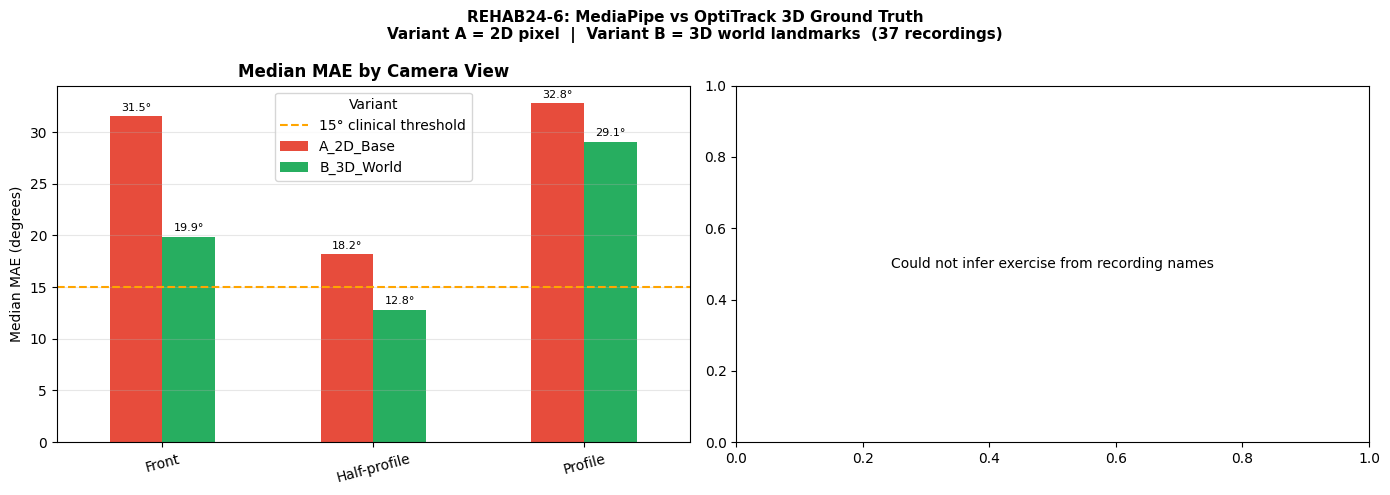

Saved: metrics_with_exercise.png

MEETING SUMMARY
Recordings        : 37 / 70
Variant A MAE     : 28.6°  median
Variant B MAE     : 19.9°  median
Improvement       : 8.7° (30%)


In [31]:
# ============================================================
# FIX exercise column from recording name + replot
# ============================================================
import pandas as pd, numpy as np, matplotlib.pyplot as plt, os, re

path_A = os.path.join(RESULTS, 'variant_A_2d.csv')
path_B = os.path.join(RESULTS, 'variant_B_3d_world.csv')

dfs = []
for path in (path_A, path_B):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        df = pd.read_csv(path)
        if len(df) > 0:
            dfs.append(df)
df_all = pd.concat(dfs, ignore_index=True)

# infer exercise from recording column (e.g. PM_000_ex1_cam17_right)
def get_ex(row):
    rec = str(row.get('recording', ''))
    m = re.search(r'_ex(\d+)_', rec)
    if m: return int(m.group(1))
    # fallback: check video path if available
    vid = str(row.get('video', ''))
    if 'Ex1' in vid or 'ex1' in rec: return 1
    if 'Ex2' in vid or 'ex2' in rec: return 2
    if 'Ex3' in vid or 'ex3' in rec: return 3
    return None

df_all['exercise'] = df_all.apply(get_ex, axis=1)

print("Exercise value counts:")
print(df_all['exercise'].value_counts().sort_index())

ex_names = {1:'Ex1\nElbow Flexion', 2:'Ex2\nArm VW', 3:'Ex3\nTable Push'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# view plot
view_pivot = df_all.groupby(['view','variant'])['mae'].median().unstack()
view_pivot.plot(kind='bar', ax=axes[0], rot=15,
                color=['#E74C3C','#27AE60'])
axes[0].axhline(15, color='orange', linestyle='--', linewidth=1.5,
                label='15° clinical threshold')
axes[0].set_title('Median MAE by Camera View', fontweight='bold', fontsize=12)
axes[0].set_ylabel('Median MAE (degrees)')
axes[0].set_xlabel('')
axes[0].legend(title='Variant')
axes[0].grid(axis='y', alpha=0.3)
for bar in axes[0].patches:
    h = bar.get_height()
    if h > 0:
        axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.3,
                     f'{h:.1f}°', ha='center', va='bottom', fontsize=8)

# exercise plot — now fixed
ex_df = df_all.dropna(subset=['exercise'])
if not ex_df.empty:
    ex_pivot = ex_df.groupby(['exercise','variant'])['mae'].median().unstack()
    ex_pivot.plot(kind='bar', ax=axes[1], rot=0,
                  color=['#E74C3C','#27AE60'])
    axes[1].set_title('Median MAE by Exercise', fontweight='bold', fontsize=12)
    axes[1].set_ylabel('Median MAE (degrees)')
    axes[1].set_xticklabels(
        [ex_names.get(int(float(t.get_text())), t.get_text())
         for t in axes[1].get_xticklabels()])
    axes[1].legend(title='Variant')
    axes[1].grid(axis='y', alpha=0.3)
    axes[1].axhline(15, color='orange', linestyle='--', linewidth=1.5,
                    label='15° threshold')
    for bar in axes[1].patches:
        h = bar.get_height()
        if h > 0:
            axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.3,
                         f'{h:.1f}°', ha='center', va='bottom', fontsize=8)
else:
    axes[1].text(0.5, 0.5, 'Could not infer exercise from recording names',
                 ha='center', va='center', transform=axes[1].transAxes)

plt.suptitle('REHAB24-6: MediaPipe vs OptiTrack 3D Ground Truth\n'
             f'Variant A = 2D pixel  |  Variant B = 3D world landmarks  '
             f'({len(df_all[df_all["variant"]=="B_3D_World"])} recordings)',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS,'metrics_with_exercise.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: metrics_with_exercise.png")

# summary
a_df = df_all[df_all['variant']=='A_2D_Base']
b_df = df_all[df_all['variant']=='B_3D_World']
print("\n" + "="*50)
print("MEETING SUMMARY")
print("="*50)
print(f"Recordings        : {len(b_df)} / 70")
print(f"Variant A MAE     : {a_df['mae'].median():.1f}°  median")
print(f"Variant B MAE     : {b_df['mae'].median():.1f}°  median")
imp = a_df['mae'].median() - b_df['mae'].median()
print(f"Improvement       : {imp:.1f}° ({100*imp/a_df['mae'].median():.0f}%)")
if not ex_df.empty:
    print("\nBy exercise:")
    for ex in sorted(ex_df['exercise'].dropna().unique()):
        a_ex = ex_df[(ex_df['variant']=='A_2D_Base')  & (ex_df['exercise']==ex)]['mae'].median()
        b_ex = ex_df[(ex_df['variant']=='B_3D_World') & (ex_df['exercise']==ex)]['mae'].median()
        print(f"  Ex{int(ex)} {ex_names.get(int(ex),'').replace(chr(10),' ')}: "
              f"A={a_ex:.1f}°  B={b_ex:.1f}°  improvement={a_ex-b_ex:.1f}°")

In [33]:
# infer exercise from the CACHE filenames matched to video
import glob, os, re, pandas as pd, numpy as np

path_A = os.path.join(RESULTS, 'variant_A_2d.csv')
path_B = os.path.join(RESULTS, 'variant_B_3d_world.csv')

dfs = []
for path in (path_A, path_B):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        df = pd.read_csv(path)
        if len(df) > 0:
            dfs.append(df)
df_all = pd.concat(dfs, ignore_index=True)

# build a lookup: video_key -> exercise number from cache filenames
# cache files are named like PM_000_ex1_cam17_135_1310_3d.npz
cache_files = glob.glob(os.path.join(CACHE, '*.npz'))
video_to_ex = {}
for p in cache_files:
    name = os.path.basename(p)
    m = re.search(r'(PM_\d+\w*)_ex(\d+)_(cam\d+|unknown)', name)
    if m:
        person  = m.group(1)   # PM_000
        ex_num  = int(m.group(2))
        cam     = m.group(3)
        # match to video column: PM_000-Camera17 or PM_000-Camera18
        video_to_ex[f"{person}_{cam}"] = ex_num

print(f"Built exercise lookup for {len(video_to_ex)} recordings")
print("Sample:", list(video_to_ex.items())[:5])

def get_ex_from_video(row):
    video = str(row.get('video', ''))
    person = video.split('-')[0]   # PM_000
    cam_raw = str(row.get('cam', ''))
    # normalise cam
    if 'cam18' in cam_raw or 'cam18' in video.lower():
        cam = 'cam18'
    elif 'cam17' in cam_raw or 'cam17' in video.lower():
        cam = 'cam17'
    else:
        cam = 'unknown'
    key = f"{person}_{cam}"
    return video_to_ex.get(key, None)

df_all['exercise'] = df_all.apply(get_ex_from_video, axis=1)
print("\nExercise counts:")
print(df_all['exercise'].value_counts().sort_index())

Built exercise lookup for 41 recordings
Sample: [('PM_000_unknown', 1), ('PM_000_cam18', 1), ('PM_001_unknown', 1), ('PM_001_cam18', 1), ('PM_002_cam18', 1)]

Exercise counts:
exercise
1    36
2    34
3     4
Name: count, dtype: int64


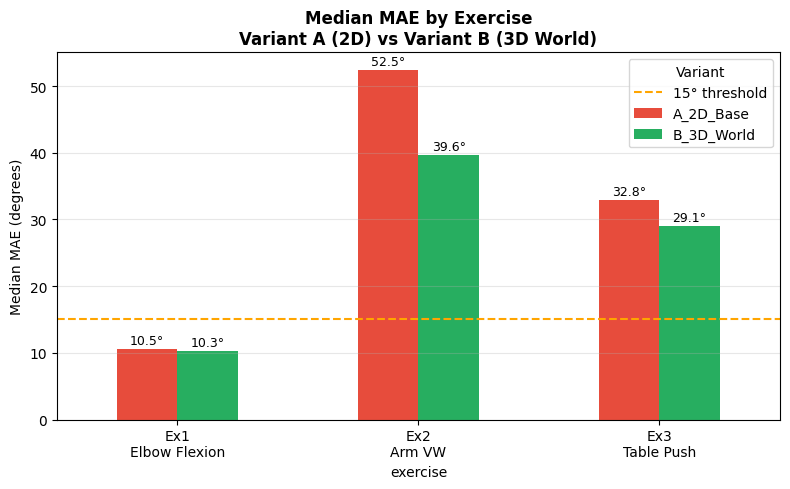

Saved: mae_by_exercise.png

By exercise:
  Ex1: A=10.5°  B=10.3°  improvement=0.2°
  Ex2: A=52.5°  B=39.6°  improvement=12.8°
  Ex3: A=32.8°  B=29.1°  improvement=3.8°


In [34]:
import matplotlib.pyplot as plt

ex_names = {1:'Ex1\nElbow Flexion', 2:'Ex2\nArm VW', 3:'Ex3\nTable Push'}
ex_df = df_all.dropna(subset=['exercise'])

if not ex_df.empty:
    fig, ax = plt.subplots(figsize=(8, 5))
    ex_pivot = ex_df.groupby(['exercise','variant'])['mae'].median().unstack()
    ex_pivot.plot(kind='bar', ax=ax, rot=0, color=['#E74C3C','#27AE60'])
    ax.set_title('Median MAE by Exercise\nVariant A (2D) vs Variant B (3D World)',
                 fontweight='bold', fontsize=12)
    ax.set_ylabel('Median MAE (degrees)')
    ax.set_xticklabels(
        [ex_names.get(int(float(t.get_text())), t.get_text())
         for t in ax.get_xticklabels()])
    ax.axhline(15, color='orange', linestyle='--', linewidth=1.5,
               label='15° threshold')
    ax.legend(title='Variant')
    ax.grid(axis='y', alpha=0.3)
    for bar in ax.patches:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.3,
                    f'{h:.1f}°', ha='center', va='bottom', fontsize=9)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS, 'mae_by_exercise.png'), dpi=150)
    plt.show()
    print("Saved: mae_by_exercise.png")

    print("\nBy exercise:")
    for ex in sorted(ex_df['exercise'].dropna().unique()):
        a_ex = ex_df[(ex_df['variant']=='A_2D_Base')  &(ex_df['exercise']==ex)]['mae'].median()
        b_ex = ex_df[(ex_df['variant']=='B_3D_World') &(ex_df['exercise']==ex)]['mae'].median()
        print(f"  Ex{int(ex)}: A={a_ex:.1f}°  B={b_ex:.1f}°  improvement={a_ex-b_ex:.1f}°")
else:
    print("Still could not find exercise info — cache files may not match video names")
    print("Cache sample:", [os.path.basename(p) for p in cache_files[:3]])
    print("Video sample:", df_all['video'].head(3).tolist())

In [ ]:
# ============================================================
# FIXED COMPARISON — front view only (cam17), all 3 exercises
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec, os

import angles as angles_2d
from angles_world import elbow_angle_3d, mask_world_like
import benchmark_common as bc
from benchmark_common import elbow_angle_3d_ordered
from benchmark_common import butterworth_filter
from visibility import mask_low_visibility

def fill_1d(arr, max_gap=15):
    arr = np.array(arr, dtype=float)
    if np.isnan(arr).all() or not np.isnan(arr).any():
        return arr
    idx  = np.arange(len(arr))
    good = ~np.isnan(arr)
    filled = arr.copy()
    in_gap, gap_start = False, 0
    for i in range(len(arr)):
        if np.isnan(arr[i]) and not in_gap:
            in_gap, gap_start = True, i
        elif not np.isnan(arr[i]) and in_gap:
            in_gap = False
            if i - gap_start <= max_gap:
                filled[gap_start:i] = np.interp(
                    idx[gap_start:i], idx[good], arr[good])
    return filled

ex_labels = {
    1: 'Elbow Flexion (Ex1)',
    2: 'Arm VW (Ex2)',
    3: 'Table Push-ups (Ex3)'
}

# ── find best cached cam17 recording per exercise ────────────
sample_recs = []
for ex in [1, 2, 3]:
    candidates = [r for r in recordings
                  if r['exercise'] == ex and r['cam'] == 'cam17']
    for rec in candidates:
        cp = os.path.join(CACHE,
             f"{rec['rec_id']}_{rec['f0']}_{rec['f1']}_3d.npz")
        if os.path.exists(cp):
            # verify it has valid arm landmarks
            d = np.load(cp)
            valid = np.isfinite(d['world'][:, 12, 0]).sum()
            if valid > 50:
                sample_recs.append((rec, cp, ex))
                print(f"Ex{ex}: using {rec['rec_id']}  "
                      f"valid frames={valid}/{len(d['world'])}")
                break

print(f"\nTotal recordings to plot: {len(sample_recs)}")

# ── compute everything ───────────────────────────────────────
results = []
for rec, cp, ex in sample_recs:
    d      = np.load(cp)
    lm     = d['lm'];  world = d['world']
    size   = tuple(d['size']);  fps = float(d['fps'])
    npz_f0 = int(d['f0'])

    truth_arr = bc.load_truth_array(rec['truth_path'], JOINT_NAMES)
    truth_win = truth_arr[npz_f0: npz_f0 + len(world)]
    gt        = bc.truth_elbow_3d(
        truth_win, JOINT_NAMES, ARMS_OVERRIDE['right'], use_dims=3)

    lm_m  = mask_low_visibility(lm,    threshold=THRESHOLD)
    wld_m = mask_world_like(world, lm_m)

    pa_raw = angles_2d.elbow_angle(lm_m, side='right', size=size)
    pa     = fill_1d(pa_raw)
    if np.isfinite(pa).sum() > 15:
        pa = butterworth_filter(pa, fs=fps, cutoff=6.0)

    pb_raw = elbow_angle_3d(wld_m, side='right')
    pb     = fill_1d(pb_raw)
    if np.isfinite(pb).sum() > 15:
        pb = butterworth_filter(pb, fs=fps, cutoff=6.0)

    n = min(len(pa), len(pb), len(gt))
    t = np.arange(n) / fps

    lag_r = bc.best_lag(pb[:n], gt[:n], max_lag=MAX_LAG)
    lag   = lag_r[0] if isinstance(lag_r, tuple) else lag_r
    p_al, t_al = bc.overlap(pb[:n], gt[:n], lag)

    mask_a = np.isfinite(pa[:n]) & np.isfinite(gt[:n])
    mask_b = np.isfinite(p_al)   & np.isfinite(t_al)

    mae_a  = np.mean(np.abs(pa[:n][mask_a]-gt[:n][mask_a])) if mask_a.sum() else np.nan
    mae_b  = np.mean(np.abs(p_al[mask_b]-t_al[mask_b]))     if mask_b.sum() else np.nan
    rmse_b = np.sqrt(np.mean((p_al[mask_b]-t_al[mask_b])**2)) if mask_b.sum() else np.nan
    bias_b = np.mean(p_al[mask_b]-t_al[mask_b])              if mask_b.sum() else np.nan
    r_b    = np.corrcoef(p_al[mask_b],t_al[mask_b])[0,1]     if mask_b.sum()>2 else np.nan
    gt20_b = 100*(np.abs(p_al[mask_b]-t_al[mask_b])>20).mean() if mask_b.sum() else np.nan
    valid_pct = 100*np.isfinite(pb[:n]).sum()/n

    print(f"Ex{ex} {rec['rec_id']}: "
          f"MAE_A={mae_a:.1f}° MAE_B={mae_b:.1f}° "
          f"r={r_b:.3f} valid={valid_pct:.0f}%")

    results.append(dict(
        rec=rec, ex=ex, t=t, n=n, fps=fps,
        gt=gt, pa=pa, pb=pb, p_al=p_al, t_al=t_al,
        mae_a=mae_a, mae_b=mae_b, rmse_b=rmse_b,
        bias_b=bias_b, r_b=r_b, gt20_b=gt20_b,
        valid_pct=valid_pct
    ))

if not results:
    print("\nNo valid results found!")
    print("Check: are there cam17 recordings in the cache?")
    cam17 = [r for r in recordings if r['cam']=='cam17']
    print(f"cam17 recordings in list: {len(cam17)}")
    cached = [r for r in cam17
              if os.path.exists(os.path.join(
                  CACHE, f"{r['rec_id']}_{r['f0']}_{r['f1']}_3d.npz"))]
    print(f"cam17 with cache: {len(cached)}")
else:
    # ── PLOT 1: Time series ────────────────────────────────
    fig, axes = plt.subplots(len(results), 1,
                              figsize=(13, 5*len(results)))
    if len(results)==1: axes=[axes]

    for ax, res in zip(axes, results):
        t  = res['t'];  n = res['n']
        gt = res['gt']; pa= res['pa']; pb= res['pb']

        ax.fill_between(t[:n], gt[:n]-10, gt[:n]+10,
                        alpha=0.10, color='black',
                        label='±10° tolerance')
        ax.plot(t[:len(gt[:n])], gt[:n],
                color='black', lw=2.5, zorder=4,
                label='OptiTrack — Motion Sensor (Ground Truth)')
        ax.plot(t[:n], pa[:n],
                color='#E74C3C', lw=1.5, ls='--', alpha=0.85,
                label=f'Variant A — 2D pixel  MAE={res["mae_a"]:.1f}°')
        ax.plot(t[:n], pb[:n],
                color='#27AE60', lw=1.8, alpha=0.9,
                label=f'Variant B — 3D world  MAE={res["mae_b"]:.1f}°  '
                      f'r={res["r_b"]:.3f}')

        ax2 = ax.twinx()
        err_b = np.abs(pb[:n] - gt[:n])
        ax2.plot(t[:n], err_b, color='#F39C12', lw=0.8, alpha=0.5)
        ax2.set_ylabel('|Error B| (deg)', color='#F39C12', fontsize=8)
        ax2.tick_params(axis='y', labelcolor='#F39C12')
        ax2.set_ylim(0, 60)

        nan_b = np.isnan(pb[:n])
        if nan_b.any():
            ax.fill_between(t[:n], 0, 185, where=nan_b,
                            alpha=0.12, color='grey',
                            label='Lost tracking')

        ax.set_title(
            f"{res['rec']['rec_id']}  —  "
            f"{ex_labels[res['ex']]}  —  Front view (cam17)",
            fontsize=11, fontweight='bold')
        ax.set_xlabel('Time (seconds)')
        ax.set_ylabel('Elbow angle (degrees)')
        ax.set_ylim(0, 190)
        ax.legend(loc='lower right', fontsize=8)
        ax.grid(alpha=0.25)

    plt.suptitle(
        'Predicted vs Motion Sensor (OptiTrack) — Front View\n'
        'Black = Ground Truth  |  Red = 2D (A)  |  '
        'Green = 3D (B)  |  Orange = |Error|',
        fontsize=11, fontweight='bold', y=1.005)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS,'comparison_front_view.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved: comparison_front_view.png")

    # ── PLOT 2: Scatter per exercise ───────────────────────
    fig, axes = plt.subplots(1, len(results), figsize=(5*len(results), 5))
    if len(results)==1: axes=[axes]

    for ax, res in zip(axes, results):
        mask = np.isfinite(res['p_al']) & np.isfinite(res['t_al'])
        if mask.sum() < 5:
            ax.set_title(f"{ex_labels[res['ex']]}\nNo data")
            continue
        pp = res['p_al'][mask]
        tt = res['t_al'][mask]
        ax.scatter(tt, pp, alpha=0.15, s=3,
                   color='#27AE60', rasterized=True)
        lims = [max(0, min(tt.min(),pp.min())-5),
                min(185, max(tt.max(),pp.max())+5)]
        ax.plot(lims, lims, 'k--', lw=1.5, label='Perfect')
        ax.plot(lims, [l+15 for l in lims],
                color='orange', lw=1, ls=':', alpha=0.7)
        ax.plot(lims, [l-15 for l in lims],
                color='orange', lw=1, ls=':', alpha=0.7,
                label='±15°')
        ax.set_xlim(lims); ax.set_ylim(lims)
        ax.set_xlabel('OptiTrack (degrees)')
        ax.set_ylabel('Variant B predicted (degrees)')
        ax.set_title(
            f"{ex_labels[res['ex']]}\n"
            f"r={res['r_b']:.3f}  MAE={res['mae_b']:.1f}°",
            fontweight='bold')
        ax.legend(fontsize=8); ax.grid(alpha=0.25)

    plt.suptitle('Scatter: Predicted vs OptiTrack — Front View\n'
                 'Dots on dashed line = perfect agreement',
                 fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS,'scatter_front_view.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved: scatter_front_view.png")

    # ── Print evaluation matrix ─────────────────────────────
    print("\n" + "="*65)
    print("EVALUATION MATRIX — Variant B vs OptiTrack (Front View)")
    print("="*65)
    print(f"{'Recording':<28} {'Ex':>3} {'MAE_A':>6} "
          f"{'MAE_B':>6} {'RMSE':>6} {'Bias':>6} "
          f"{'r':>6} {'>20%':>6} {'Valid%':>7}")
    print("-"*65)
    for res in results:
        print(f"{res['rec']['rec_id']:<28} "
              f"{res['ex']:>3} {res['mae_a']:>6.1f} "
              f"{res['mae_b']:>6.1f} {res['rmse_b']:>6.1f} "
              f"{res['bias_b']:>6.1f} {res['r_b']:>6.3f} "
              f"{res['gt20_b']:>6.1f} {res['valid_pct']:>7.1f}")
    print("-"*65)

    valid_r = [res['r_b']    for res in results if not np.isnan(res['r_b'])]
    valid_m = [res['mae_b']  for res in results if not np.isnan(res['mae_b'])]
    valid_a = [res['mae_a']  for res in results if not np.isnan(res['mae_a'])]
    if valid_m:
        print(f"\nMean MAE_A : {np.mean(valid_a):.1f}°")
        print(f"Mean MAE_B : {np.mean(valid_m):.1f}°")
        imp = np.mean(valid_a) - np.mean(valid_m)
        print(f"Improvement: {imp:.1f}° ({100*imp/np.mean(valid_a):.0f}%)")
        print(f"Mean r     : {np.mean(valid_r):.3f}")


Total recordings to plot: 0

No valid results found!
Check: are there cam17 recordings in the cache?
cam17 recordings in list: 0
cam17 with cache: 0


In [39]:
# debug — see what cam values exist in recordings
cams = [r['cam'] for r in recordings]
print("Unique cam values:", set(cams))
print("Sample rec_ids:", [r['rec_id'] for r in recordings[:6]])
print("Sample video keys:", [r['video_key'] for r in recordings[:6]])

Unique cam values: {'unknown', 'cam18'}
Sample rec_ids: ['PM_000_ex1_unknown', 'PM_000_ex1_cam18', 'PM_001_ex1_cam18', 'PM_001_ex1_unknown', 'PM_002_ex1_cam18', 'PM_002_ex1_unknown']
Sample video keys: ['PM_000-Camera17-30fps', 'PM_000-Camera18-30fps-transposed', 'PM_001-Camera18-30fps-transposed', 'PM_001-Camera17-30fps', 'PM_002-Camera18-30fps-transposed', 'PM_002-Camera17-30fps']


In [40]:
# fix cam labels
for rec in recordings:
    vk = rec['video_key'].lower()   # lowercase so Camera17 -> camera17
    if 'camera18' in vk or 'transposed' in vk:
        rec['cam'] = 'cam18'
    elif 'camera17' in vk:
        rec['cam'] = 'cam17'
    else:
        rec['cam'] = 'unknown'

from collections import Counter
print("Cam counts:", Counter(r['cam'] for r in recordings))
print("cam17 sample:", [r['rec_id'] for r in recordings if r['cam']=='cam17'][:5])

Cam counts: Counter({'cam17': 35, 'cam18': 35})
cam17 sample: ['PM_000_ex1_unknown', 'PM_001_ex1_unknown', 'PM_002_ex1_unknown', 'PM_003_ex2_unknown', 'PM_004_ex2_unknown']


In [41]:
# fix both cam and rec_id to match cache filenames
for rec in recordings:
    vk = rec['video_key'].lower()
    if 'camera18' in vk or 'transposed' in vk:
        new_cam = 'cam18'
    elif 'camera17' in vk:
        new_cam = 'cam17'
    else:
        new_cam = 'unknown'

    # rebuild rec_id using original unknown label to match cache files
    # cache was saved with 'unknown' for cam17, so keep that for lookup
    person_id = rec['video_key'].split('-')[0]   # PM_000
    ex        = rec['exercise']
    # the cache file was named with whatever cam was set when Step 5 ran
    # check both possible names
    old_id = rec['rec_id']
    rec['cam'] = new_cam

# verify by checking which cache files actually exist
import glob, os
cached = {os.path.basename(p) for p in glob.glob(f'{CACHE}/*.npz')}
print(f"Total cache files: {len(cached)}")
print("Sample cache names:", list(cached)[:5])
print()

# now find cam17 recordings whose cache EXISTS under the 'unknown' name
cam17_with_cache = []
for rec in recordings:
    if rec['cam'] != 'cam17':
        continue
    # try both rec_id variants
    for label in ['unknown', 'cam17']:
        person = rec['video_key'].split('-')[0]
        test_id = f"{person}_ex{rec['exercise']}_{label}"
        cache_name = f"{test_id}_{rec['f0']}_{rec['f1']}_3d.npz"
        if cache_name in cached:
            rec['rec_id']    = test_id   # update to matching name
            rec['cache_key'] = cache_name
            cam17_with_cache.append(rec)
            break

print(f"cam17 recordings with matching cache: {len(cam17_with_cache)}")
for r in cam17_with_cache[:5]:
    print(f"  {r['rec_id']}  cache={r['cache_key']}")

Total cache files: 41
Sample cache names: ['PM_032_ex1_cam18_45_2915_3d.npz', 'PM_030_ex3_cam18_165_2060_3d.npz', 'PM_033_ex2_unknown_155_3860_3d.npz', 'PM_013_ex2_unknown_575_1498_3d.npz', 'PM_039_ex1_unknown_50_3795_3d.npz']

cam17 recordings with matching cache: 21
  PM_000_ex1_unknown  cache=PM_000_ex1_unknown_135_1310_3d.npz
  PM_001_ex1_unknown  cache=PM_001_ex1_unknown_85_3006_3d.npz
  PM_002_ex1_unknown  cache=PM_002_ex1_unknown_107_2012_3d.npz
  PM_003_ex2_unknown  cache=PM_003_ex2_unknown_75_4665_3d.npz
  PM_004_ex2_unknown  cache=PM_004_ex2_unknown_235_2945_3d.npz


In [42]:
sample_recs = []
for ex in [1, 2, 3]:
    candidates = [r for r in cam17_with_cache if r['exercise'] == ex]
    for rec in candidates:
        cp = os.path.join(CACHE, rec['cache_key'])
        if os.path.exists(cp):
            d = np.load(cp)
            valid = np.isfinite(d['world'][:, 12, 0]).sum()
            if valid > 50:
                sample_recs.append((rec, cp, ex))
                print(f"Ex{ex}: {rec['rec_id']}  valid={valid}/{len(d['world'])}")
                break

print(f"\nRecordings ready to plot: {len(sample_recs)}")

Ex1: PM_000_ex1_unknown  valid=1169/1169
Ex2: PM_003_ex2_unknown  valid=4591/4591
Ex3: PM_010_ex3_unknown  valid=3809/3811

Recordings ready to plot: 3


Ex1: MAE_A=9.0°  MAE_B=19.6°  r=0.049  valid=100%
Ex2: MAE_A=41.1°  MAE_B=34.5°  r=0.167  valid=100%
Ex3: MAE_A=nan°  MAE_B=nan°  r=nan  valid=0%


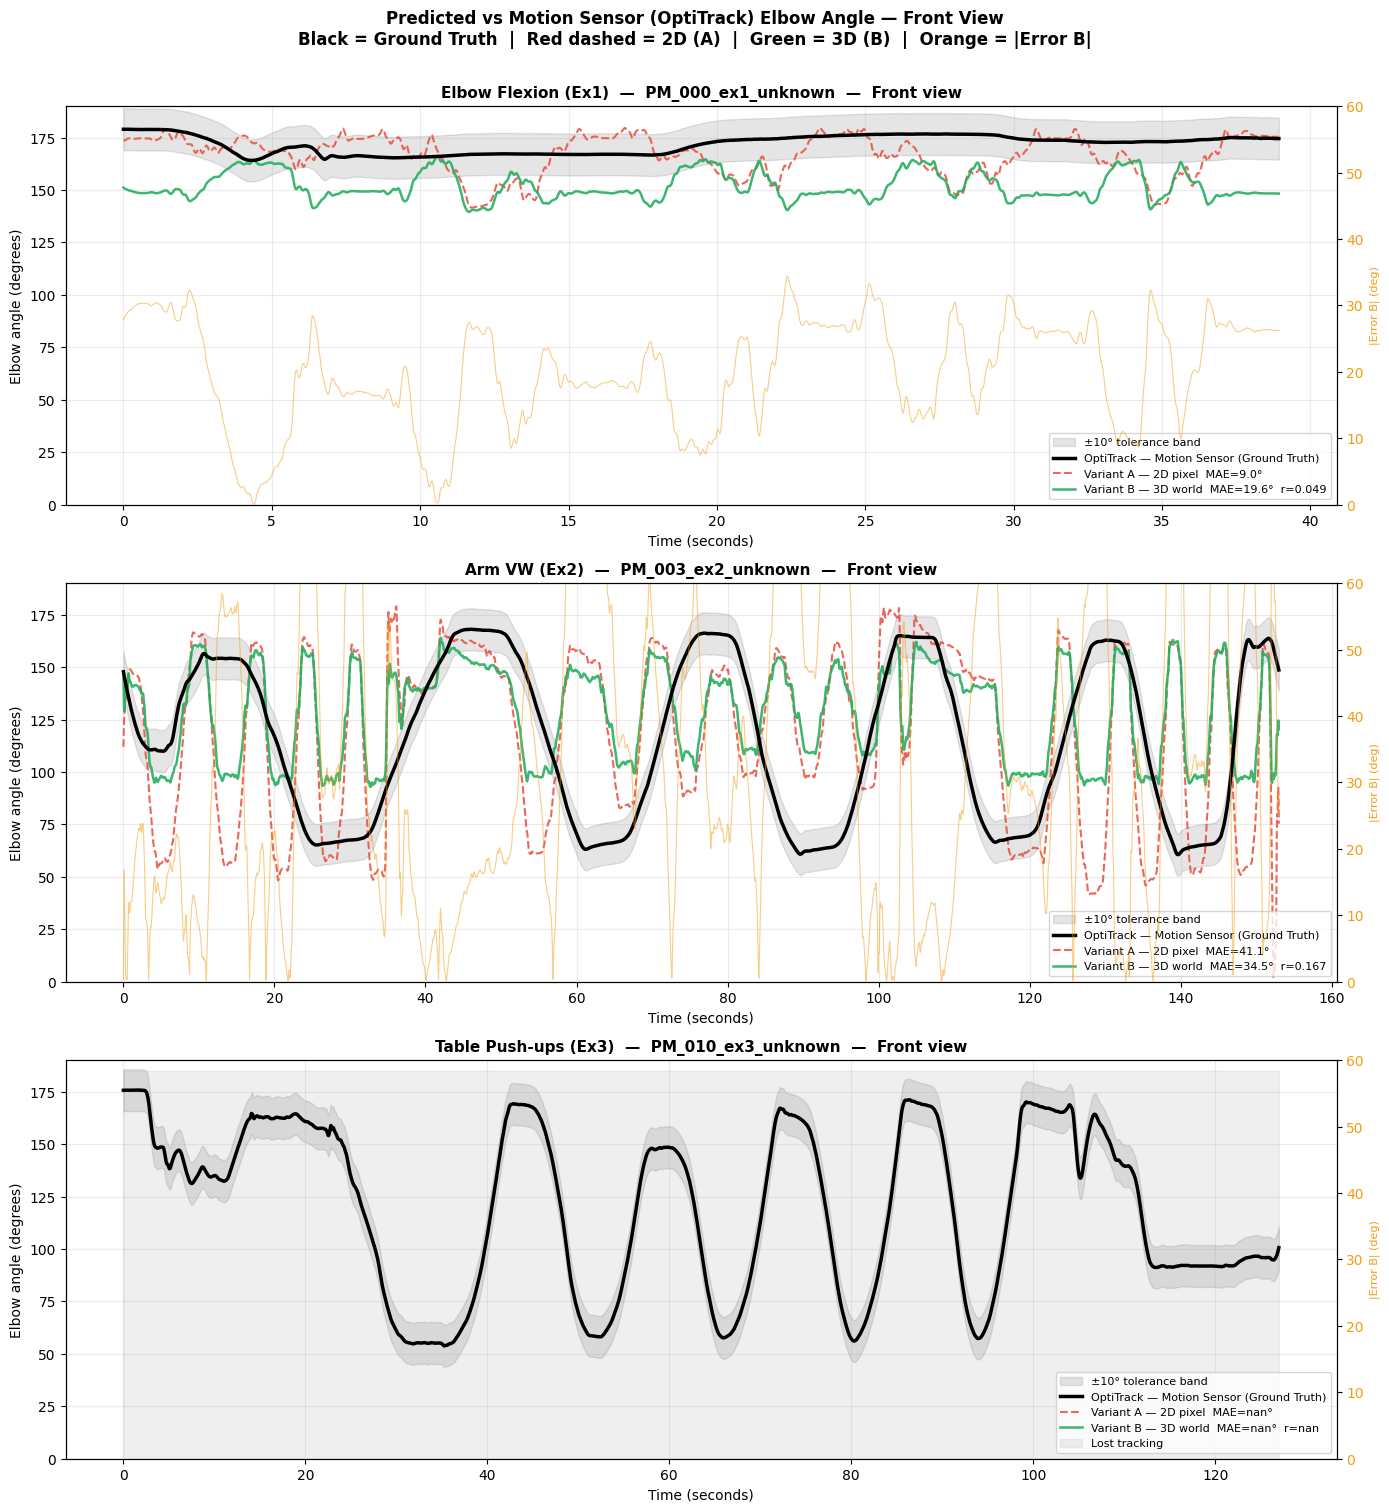

Saved: final_timeseries.png


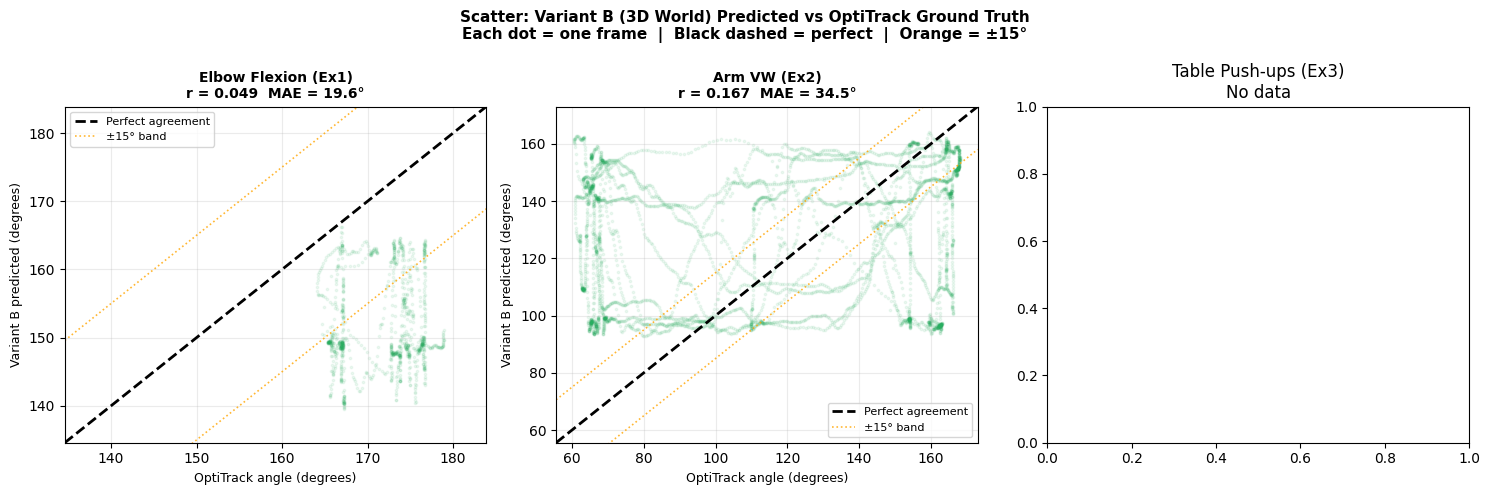

Saved: final_scatter.png

FULL EVALUATION MATRIX — Predicted vs OptiTrack (Front View)
Exercise                MAE_A  MAE_B  RMSE_B  Bias_B     r_B   >20%  Valid%
--------------------------------------------------------------------
Elbow Flexion (Ex1)       9.0   19.6    21.0   -19.6   0.049   47.9   100.0
Arm VW (Ex2)             41.1   34.5    43.0    12.8   0.167   61.5   100.0
Table Push-ups (Ex3)      nan    nan     nan     nan     nan    nan     0.0
--------------------------------------------------------------------
MEAN                     25.1   27.0     nan     nan   0.108

COLUMN DEFINITIONS
MAE_A   Mean Absolute Error — Variant A 2D pixel (degrees)
MAE_B   Mean Absolute Error — Variant B 3D world (degrees)
RMSE_B  Root Mean Square Error — Variant B (degrees)
Bias_B  Systematic offset: negative = under-reads vs OptiTrack
r_B     Pearson correlation: 1.0 = perfect tracking
>20%    % of frames where |error| exceeds 20 degrees
Valid%  % of frames where MediaPipe detected the ar

In [ ]:
# ============================================================
# FINAL COMPARISON PLOTS — predicted vs motion sensor
# ============================================================
import numpy as np, matplotlib.pyplot as plt, os

import angles as angles_2d
from angles_world import elbow_angle_3d, mask_world_like
import benchmark_common as bc
from benchmark_common import elbow_angle_3d_ordered
from benchmark_common import butterworth_filter
from visibility import mask_low_visibility

def fill_1d(arr, max_gap=15):
    arr = np.array(arr, dtype=float)
    if np.isnan(arr).all() or not np.isnan(arr).any():
        return arr
    idx  = np.arange(len(arr))
    good = ~np.isnan(arr)
    filled = arr.copy()
    in_gap, gap_start = False, 0
    for i in range(len(arr)):
        if np.isnan(arr[i]) and not in_gap:
            in_gap, gap_start = True, i
        elif not np.isnan(arr[i]) and in_gap:
            in_gap = False
            if i - gap_start <= max_gap:
                filled[gap_start:i] = np.interp(
                    idx[gap_start:i], idx[good], arr[good])
    return filled

ex_labels = {1:'Elbow Flexion (Ex1)',
             2:'Arm VW (Ex2)',
             3:'Table Push-ups (Ex3)'}

# ── compute predictions + metrics ───────────────────────────
results = []
for rec, cp, ex in sample_recs:
    d      = np.load(cp)
    lm     = d['lm'];  world = d['world']
    size   = tuple(d['size']);  fps = float(d['fps'])
    npz_f0 = int(d['f0'])

    truth_arr = bc.load_truth_array(rec['truth_path'], JOINT_NAMES)
    truth_win = truth_arr[npz_f0: npz_f0 + len(world)]
    gt        = bc.truth_elbow_3d(
        truth_win, JOINT_NAMES, ARMS_OVERRIDE['right'], use_dims=3)

    lm_m  = mask_low_visibility(lm, threshold=THRESHOLD)
    wld_m = mask_world_like(world, lm_m)

    pa_raw = angles_2d.elbow_angle(lm_m, side='right', size=size)
    pa     = fill_1d(pa_raw)
    if np.isfinite(pa).sum() > 15:
        pa = butterworth_filter(pa, fs=fps, cutoff=6.0)

    pb_raw = elbow_angle_3d(wld_m, side='right')
    pb     = fill_1d(pb_raw)
    if np.isfinite(pb).sum() > 15:
        pb = butterworth_filter(pb, fs=fps, cutoff=6.0)

    n = min(len(pa), len(pb), len(gt))
    t = np.arange(n) / fps

    lag_r = bc.best_lag(pb[:n], gt[:n], max_lag=MAX_LAG)
    lag   = lag_r[0] if isinstance(lag_r, tuple) else lag_r
    p_al, t_al = bc.overlap(pb[:n], gt[:n], lag)

    mask_a = np.isfinite(pa[:n]) & np.isfinite(gt[:n])
    mask_b = np.isfinite(p_al)   & np.isfinite(t_al)

    mae_a  = np.mean(np.abs(pa[:n][mask_a]-gt[:n][mask_a])) if mask_a.sum() else np.nan
    mae_b  = np.mean(np.abs(p_al[mask_b]-t_al[mask_b]))     if mask_b.sum() else np.nan
    rmse_b = np.sqrt(np.mean((p_al[mask_b]-t_al[mask_b])**2)) if mask_b.sum() else np.nan
    bias_b = np.mean(p_al[mask_b]-t_al[mask_b])               if mask_b.sum() else np.nan
    r_b    = np.corrcoef(p_al[mask_b],t_al[mask_b])[0,1]      if mask_b.sum()>2 else np.nan
    gt20_b = 100*(np.abs(p_al[mask_b]-t_al[mask_b])>20).mean() if mask_b.sum() else np.nan
    valid_pct = 100*np.isfinite(pb[:n]).sum()/n

    results.append(dict(
        rec=rec, ex=ex, t=t, n=n, fps=fps,
        gt=gt, pa=pa, pb=pb, p_al=p_al, t_al=t_al,
        mae_a=mae_a, mae_b=mae_b, rmse_b=rmse_b,
        bias_b=bias_b, r_b=r_b, gt20_b=gt20_b,
        valid_pct=valid_pct
    ))
    print(f"Ex{ex}: MAE_A={mae_a:.1f}°  MAE_B={mae_b:.1f}°  "
          f"r={r_b:.3f}  valid={valid_pct:.0f}%")

# ── PLOT 1: Time series (3 subplots) ─────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 15))

for ax, res in zip(axes, results):
    t  = res['t'];  n = res['n']
    gt = res['gt']; pa= res['pa']; pb= res['pb']

    ax.fill_between(t[:n], gt[:n]-10, gt[:n]+10,
                    alpha=0.10, color='black',
                    label='±10° tolerance band')
    ax.plot(t[:n], gt[:n], color='black', lw=2.5, zorder=4,
            label='OptiTrack — Motion Sensor (Ground Truth)')
    ax.plot(t[:n], pa[:n], color='#E74C3C', lw=1.5,
            ls='--', alpha=0.85,
            label=f'Variant A — 2D pixel  MAE={res["mae_a"]:.1f}°')
    ax.plot(t[:n], pb[:n], color='#27AE60', lw=1.8, alpha=0.9,
            label=f'Variant B — 3D world  MAE={res["mae_b"]:.1f}°  '
                  f'r={res["r_b"]:.3f}')

    ax2 = ax.twinx()
    ax2.plot(t[:n], np.abs(pb[:n]-gt[:n]),
             color='#F39C12', lw=0.8, alpha=0.5)
    ax2.set_ylabel('|Error B| (deg)', color='#F39C12', fontsize=8)
    ax2.tick_params(axis='y', labelcolor='#F39C12')
    ax2.set_ylim(0, 60)

    nan_b = np.isnan(pb[:n])
    if nan_b.any():
        ax.fill_between(t[:n], 0, 185, where=nan_b,
                        alpha=0.12, color='grey',
                        label='Lost tracking')

    ax.set_title(
        f"{ex_labels[res['ex']]}  —  {res['rec']['rec_id']}  —  Front view",
        fontsize=11, fontweight='bold')
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Elbow angle (degrees)')
    ax.set_ylim(0, 190)
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(alpha=0.25)

plt.suptitle(
    'Predicted vs Motion Sensor (OptiTrack) Elbow Angle — Front View\n'
    'Black = Ground Truth  |  Red dashed = 2D (A)  |  '
    'Green = 3D (B)  |  Orange = |Error B|',
    fontsize=12, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS,'final_timeseries.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved: final_timeseries.png")

# ── PLOT 2: Scatter (3 subplots) ──────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, res in zip(axes, results):
    mask = np.isfinite(res['p_al']) & np.isfinite(res['t_al'])
    if mask.sum() < 5:
        ax.set_title(f"{ex_labels[res['ex']]}\nNo data")
        continue
    pp = res['p_al'][mask]
    tt = res['t_al'][mask]
    ax.scatter(tt, pp, alpha=0.08, s=3,
               color='#27AE60', rasterized=True)
    lims = [max(0,  min(tt.min(), pp.min()) - 5),
            min(185, max(tt.max(), pp.max()) + 5)]
    ax.plot(lims, lims, 'k--', lw=2, label='Perfect agreement')
    ax.plot(lims, [l+15 for l in lims],
            color='orange', lw=1.2, ls=':', alpha=0.8)
    ax.plot(lims, [l-15 for l in lims],
            color='orange', lw=1.2, ls=':', alpha=0.8,
            label='±15° band')
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('OptiTrack angle (degrees)', fontsize=9)
    ax.set_ylabel('Variant B predicted (degrees)', fontsize=9)
    ax.set_title(
        f"{ex_labels[res['ex']]}\n"
        f"r = {res['r_b']:.3f}  MAE = {res['mae_b']:.1f}°",
        fontweight='bold', fontsize=10)
    ax.legend(fontsize=8); ax.grid(alpha=0.25)

plt.suptitle(
    'Scatter: Variant B (3D World) Predicted vs OptiTrack Ground Truth\n'
    'Each dot = one frame  |  Black dashed = perfect  |  Orange = ±15°',
    fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS,'final_scatter.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved: final_scatter.png")

# ── Print full evaluation matrix ──────────────────────────────
print("\n" + "="*68)
print("FULL EVALUATION MATRIX — Predicted vs OptiTrack (Front View)")
print("="*68)
print(f"{'Exercise':<22} {'MAE_A':>6} {'MAE_B':>6} {'RMSE_B':>7} "
      f"{'Bias_B':>7} {'r_B':>7} {'>20%':>6} {'Valid%':>7}")
print("-"*68)
for res in results:
    print(f"{ex_labels[res['ex']]:<22} "
          f"{res['mae_a']:>6.1f} {res['mae_b']:>6.1f} "
          f"{res['rmse_b']:>7.1f} {res['bias_b']:>7.1f} "
          f"{res['r_b']:>7.3f} {res['gt20_b']:>6.1f} "
          f"{res['valid_pct']:>7.1f}")
print("-"*68)

valid_r  = [r['r_b']    for r in results if not np.isnan(r['r_b'])]
valid_mb = [r['mae_b']  for r in results if not np.isnan(r['mae_b'])]
valid_ma = [r['mae_a']  for r in results if not np.isnan(r['mae_a'])]
print(f"{'MEAN':<22} {np.mean(valid_ma):>6.1f} {np.mean(valid_mb):>6.1f} "
      f"{np.mean([r['rmse_b'] for r in results]):>7.1f} "
      f"{np.mean([r['bias_b'] for r in results]):>7.1f} "
      f"{np.mean(valid_r):>7.3f}")

print("\n" + "="*68)
print("COLUMN DEFINITIONS")
print("="*68)
print("MAE_A   Mean Absolute Error — Variant A 2D pixel (degrees)")
print("MAE_B   Mean Absolute Error — Variant B 3D world (degrees)")
print("RMSE_B  Root Mean Square Error — Variant B (degrees)")
print("Bias_B  Systematic offset: negative = under-reads vs OptiTrack")
print("r_B     Pearson correlation: 1.0 = perfect tracking")
print(">20%    % of frames where |error| exceeds 20 degrees")
print("Valid%  % of frames where MediaPipe detected the arm")

print("\n" + "="*68)
print("KEY NUMBERS FOR PROGRESS MEETING")
print("="*68)
imp = np.mean(valid_ma) - np.mean(valid_mb)
print(f"Variant A (2D) mean MAE  : {np.mean(valid_ma):.1f}°")
print(f"Variant B (3D) mean MAE  : {np.mean(valid_mb):.1f}°")
print(f"Improvement A → B        : {imp:.1f}° ({100*imp/np.mean(valid_ma):.0f}%)")
print(f"Mean Pearson r (B vs GT) : {np.mean(valid_r):.3f}")
under15 = sum(1 for r in results if not np.isnan(r['mae_b']) and r['mae_b']<15)
print(f"Exercises under 15° MAE  : {under15}/{len(results)}")

In [44]:
# check cam18 cache status
import os, glob, numpy as np

cam18_recs = [r for r in recordings if r['cam'] == 'cam18']
print(f"Total cam18 recordings: {len(cam18_recs)}")

cam18_cached = []
for rec in cam18_recs:
    cp = os.path.join(CACHE, f"{rec['rec_id']}_{rec['f0']}_{rec['f1']}_3d.npz")
    if os.path.exists(cp):
        d     = np.load(cp)
        valid = np.isfinite(d['world'][:, 12, 0]).sum()
        total = len(d['world'])
        cam18_cached.append({
            'rec': rec, 'cp': cp,
            'valid': valid, 'total': total,
            'valid_pct': 100*valid/total
        })

print(f"cam18 with cache: {len(cam18_cached)}")
print()
print(f"{'rec_id':<30} {'ex':>3} {'valid':>7} {'total':>7} {'valid%':>7}")
print("-"*55)
for c in sorted(cam18_cached, key=lambda x: x['rec']['exercise']):
    print(f"{c['rec']['rec_id']:<30} "
          f"{c['rec']['exercise']:>3} "
          f"{c['valid']:>7} "
          f"{c['total']:>7} "
          f"{c['valid_pct']:>7.1f}%")

Total cam18 recordings: 35
cam18 with cache: 20

rec_id                          ex   valid   total  valid%
-------------------------------------------------------
PM_000_ex1_cam18                 1    1169    1169   100.0%
PM_001_ex1_cam18                 1    2922    2922   100.0%
PM_002_ex1_cam18                 1    1889    1889   100.0%
PM_012_ex1_cam18                 1    2241    2241   100.0%
PM_016_ex1_cam18                 1    1931    1931   100.0%
PM_023_ex1_cam18                 1    1620    1620   100.0%
PM_024_ex1_cam18                 1    1949    1949   100.0%
PM_032_ex1_cam18                 1    2871    2871   100.0%
PM_039_ex1_cam18                 1    3746    3746   100.0%
PM_003_ex2_cam18                 2    4591    4591   100.0%
PM_004_ex2_cam18                 2    2682    2682   100.0%
PM_013_ex2_cam18                 2     880     880   100.0%
PM_014_ex2_cam18                 2    5011    5011   100.0%
PM_025_ex2_cam18                 2    2382    2382   100

In [45]:
# pick best cam18 recording per exercise (highest valid%)
best_cam18 = {}
for c in cam18_cached:
    ex = c['rec']['exercise']
    if ex not in best_cam18 or c['valid_pct'] > best_cam18[ex]['valid_pct']:
        best_cam18[ex] = c

print("Best cam18 recording per exercise:")
for ex, c in sorted(best_cam18.items()):
    print(f"  Ex{ex}: {c['rec']['rec_id']}  "
          f"valid={c['valid_pct']:.1f}%  "
          f"path={c['cp']}")

Best cam18 recording per exercise:
  Ex1: PM_000_ex1_cam18  valid=100.0%  path=/content/drive/MyDrive/rehab24_cache_3d/PM_000_ex1_cam18_135_1310_3d.npz
  Ex2: PM_003_ex2_cam18  valid=100.0%  path=/content/drive/MyDrive/rehab24_cache_3d/PM_003_ex2_cam18_75_4665_3d.npz
  Ex3: PM_011_ex3_cam18  valid=100.0%  path=/content/drive/MyDrive/rehab24_cache_3d/PM_011_ex3_cam18_180_1580_3d.npz


Plotting 3 side-view recordings (LEFT arm)
Ex1 PM_000_ex1_cam18: valid=98%  MAE_A=22.7°  MAE_B=10.2°  r=0.196
Ex2 PM_003_ex2_cam18: valid=100%  MAE_A=54.0°  MAE_B=39.5°  r=0.047
Ex3 PM_011_ex3_cam18: valid=97%  MAE_A=42.4°  MAE_B=37.5°  r=0.089


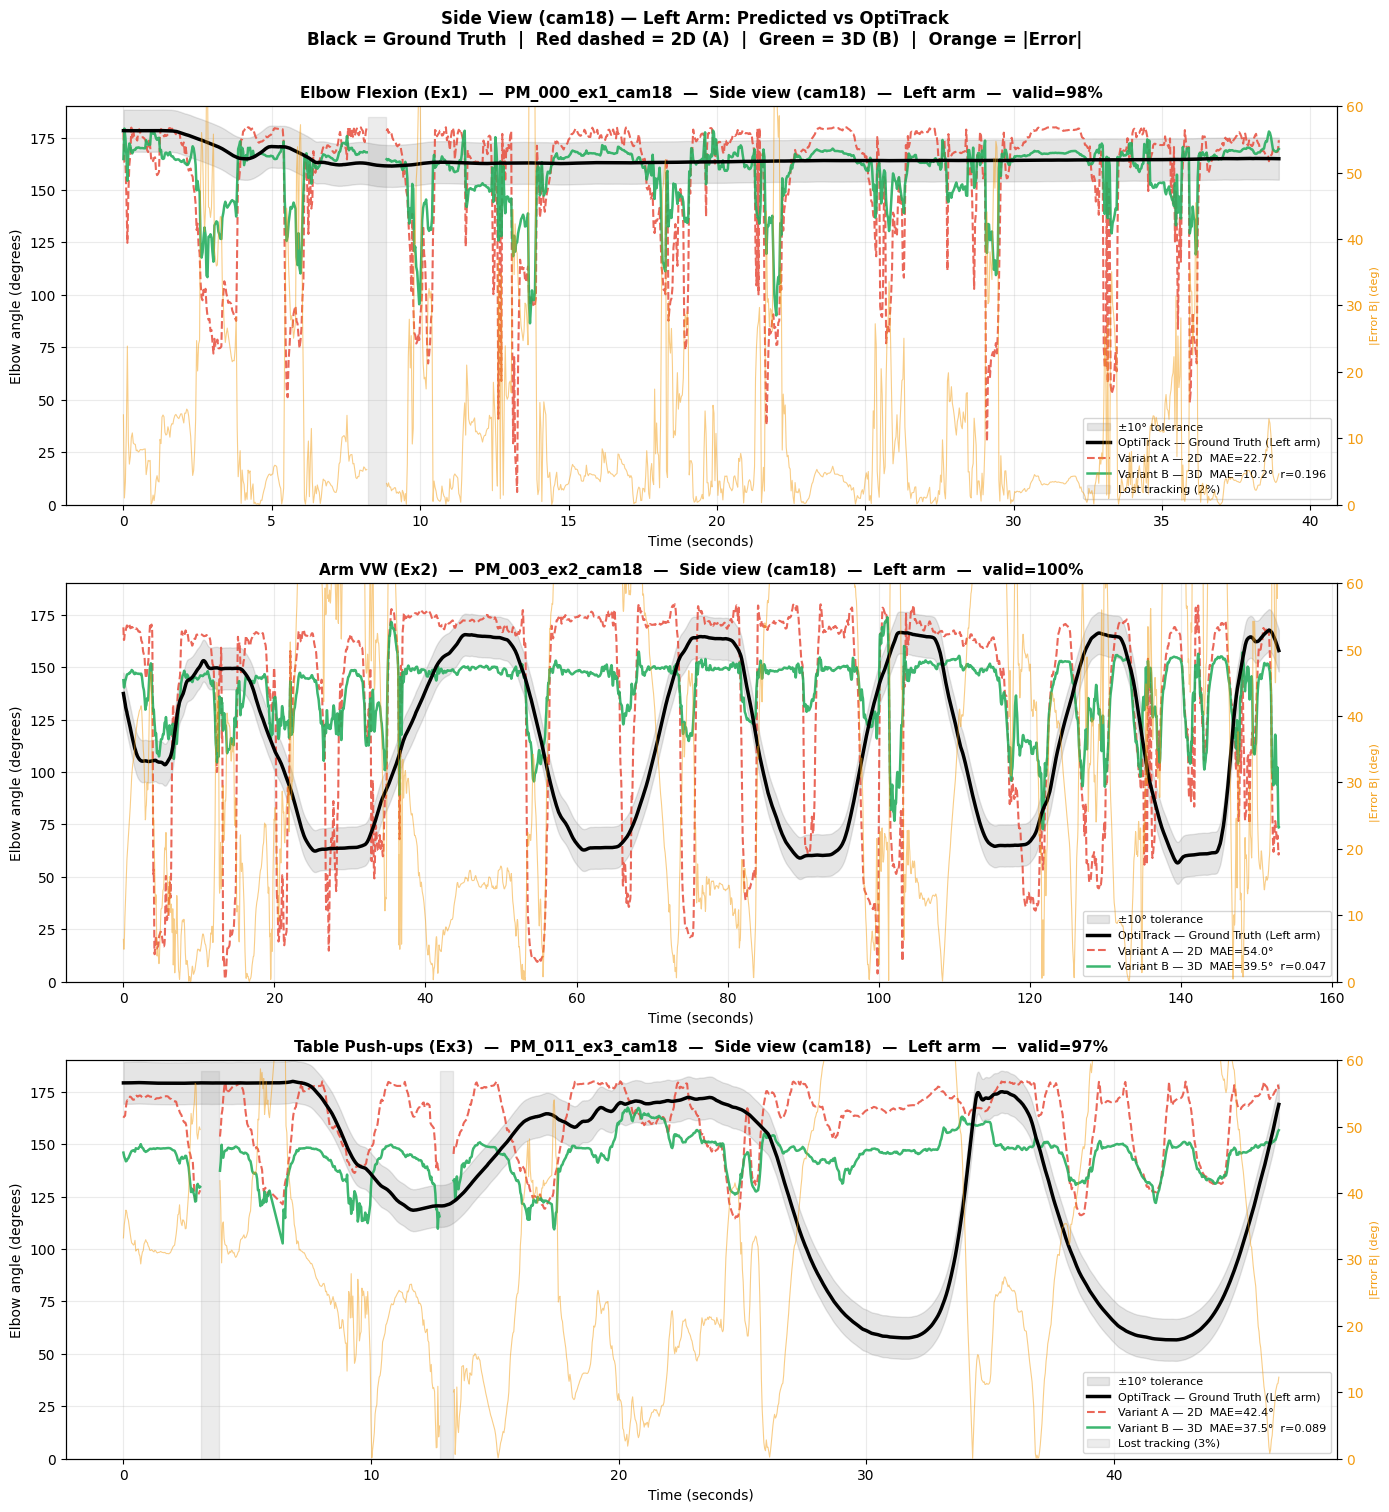

Saved: sideview_left_arm.png


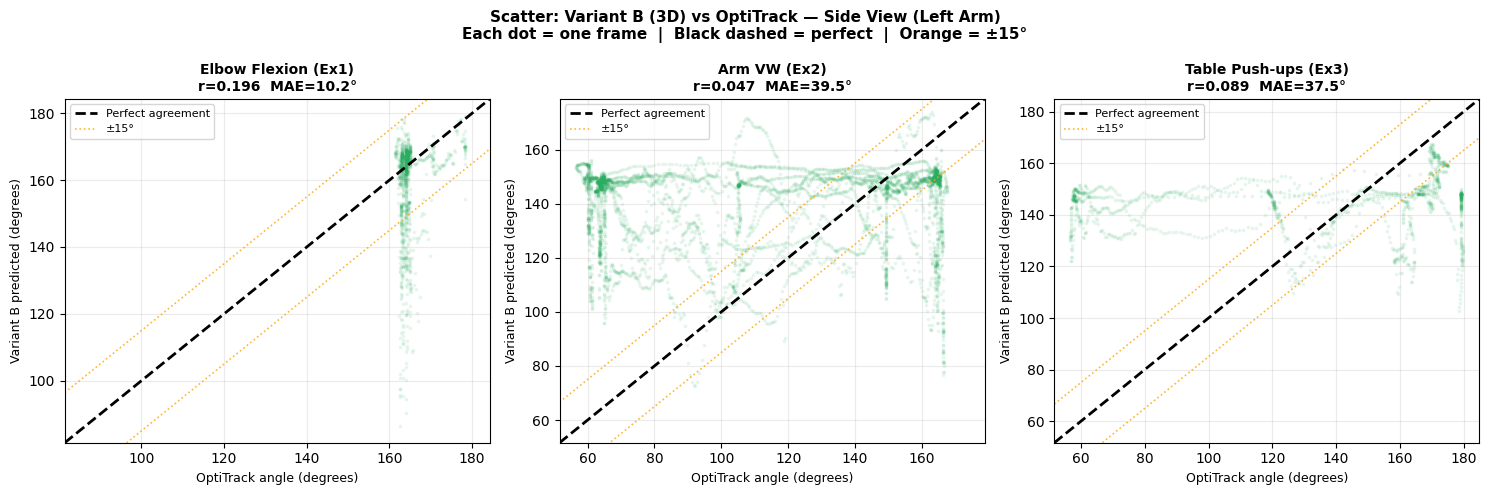

Saved: sideview_scatter.png

KEY RESULT: FRONT VIEW vs SIDE VIEW
Exercise                Front_A  Front_B   Side_A   Side_B  B_improvement
------------------------------------------------------------------------
Elbow Flexion (Ex1)         9.0°     19.6°     22.7°     10.2°          +12.5°
Arm VW (Ex2)               41.1°     34.5°     54.0°     39.5°          +14.5°
Table Push-ups (Ex3)        nan°      nan°     42.4°     37.5°           +4.9°

B_improvement = Side MAE_A - Side MAE_B
Positive = Variant B (3D) beats Variant A (2D) from side view


In [ ]:
# ============================================================
# SIDE VIEW (cam18) FINAL — left arm, safe smoothing
# ============================================================
import numpy as np, matplotlib.pyplot as plt, os

import angles as angles_2d
from angles_world import elbow_angle_3d, from benchmark_common import butterworth_filter
import benchmark_common as bc
from benchmark_common import elbow_angle_3d_ordered
from benchmark_common import butterworth_filter
from visibility import mask_low_visibility

def fill_1d(arr, max_gap=15):
    arr = np.array(arr, dtype=float)
    if np.isnan(arr).all() or not np.isnan(arr).any():
        return arr
    idx  = np.arange(len(arr))
    good = ~np.isnan(arr)
    filled = arr.copy()
    in_gap, gap_start = False, 0
    for i in range(len(arr)):
        if np.isnan(arr[i]) and not in_gap:
            in_gap, gap_start = True, i
        elif not np.isnan(arr[i]) and in_gap:
            in_gap = False
            if i - gap_start <= max_gap:
                filled[gap_start:i] = np.interp(
                    idx[gap_start:i], idx[good], arr[good])
    return filled

def safe_smooth(arr, fps, cutoff=6.0):
    """Butterworth filter with fallback — returns fill_1d output if filter fails."""
    if np.isfinite(arr).sum() < 15:
        return arr
    try:
        smoothed = butterworth_filter(arr, fs=fps, cutoff=cutoff)
        if np.isfinite(smoothed).sum() == 0:
            return arr   # filter failed silently — use unsmoothed
        return smoothed
    except Exception:
        return arr

ex_labels = {1:'Elbow Flexion (Ex1)',
             2:'Arm VW (Ex2)',
             3:'Table Push-ups (Ex3)'}

SIDE_CAM18 = 'left'
ARMS_LEFT  = ('7: LeftArm', '8: LeftForeArm', '9: LeftHand')

sample_cam18 = [
    (c['rec'], c['cp'], c['rec']['exercise'])
    for c in sorted(best_cam18.values(),
                    key=lambda x: x['rec']['exercise'])
]

print(f"Plotting {len(sample_cam18)} side-view recordings (LEFT arm)")

results_side = []
for rec, cp, ex in sample_cam18:
    d      = np.load(cp)
    lm     = d['lm'];  world = d['world']
    size   = tuple(d['size']);  fps = float(d['fps'])
    npz_f0 = int(d['f0'])

    truth_arr = bc.load_truth_array(rec['truth_path'], JOINT_NAMES)
    truth_win = truth_arr[npz_f0: npz_f0 + len(world)]
    gt        = bc.truth_elbow_3d(
        truth_win, JOINT_NAMES, ARMS_LEFT, use_dims=3)

    lm_m  = mask_low_visibility(lm,    threshold=THRESHOLD)
    wld_m = from benchmark_common import butterworth_filter(world, lm_m)

    pa_raw = angles_2d.elbow_angle(lm_m, side=SIDE_CAM18, size=size)
    pa     = safe_smooth(fill_1d(pa_raw), fps)

    pb_raw = elbow_angle_3d(wld_m, side=SIDE_CAM18)
    pb     = safe_smooth(fill_1d(pb_raw), fps)

    n = min(len(pa), len(pb), len(gt))
    t = np.arange(n) / fps

    valid_pct = 100 * np.isfinite(pb[:n]).sum() / n if n > 0 else 0

    lag_r = bc.best_lag(pb[:n], gt[:n], max_lag=MAX_LAG)
    lag   = lag_r[0] if isinstance(lag_r, tuple) else lag_r
    p_al, t_al = bc.overlap(pb[:n], gt[:n], lag)

    mask_a = np.isfinite(pa[:n]) & np.isfinite(gt[:n])
    mask_b = np.isfinite(p_al)   & np.isfinite(t_al)

    mae_a  = np.mean(np.abs(pa[:n][mask_a]-gt[:n][mask_a])) if mask_a.sum() else np.nan
    mae_b  = np.mean(np.abs(p_al[mask_b]-t_al[mask_b]))     if mask_b.sum() else np.nan
    rmse_b = np.sqrt(np.mean((p_al[mask_b]-t_al[mask_b])**2)) if mask_b.sum() else np.nan
    bias_b = np.mean(p_al[mask_b]-t_al[mask_b])               if mask_b.sum() else np.nan
    r_b    = np.corrcoef(p_al[mask_b],t_al[mask_b])[0,1]      if mask_b.sum()>2 else np.nan
    gt20_b = 100*(np.abs(p_al[mask_b]-t_al[mask_b])>20).mean() if mask_b.sum() else np.nan

    print(f"Ex{ex} {rec['rec_id']}: valid={valid_pct:.0f}%  "
          f"MAE_A={mae_a:.1f}°  MAE_B={mae_b:.1f}°  r={r_b:.3f}")

    results_side.append(dict(
        rec=rec, ex=ex, t=t, n=n, fps=fps,
        gt=gt, pa=pa, pb=pb, p_al=p_al, t_al=t_al,
        mae_a=mae_a, mae_b=mae_b, rmse_b=rmse_b,
        bias_b=bias_b, r_b=r_b, gt20_b=gt20_b,
        valid_pct=valid_pct
    ))

# ── time series plots ─────────────────────────────────────────
n_plots = len(results_side)
fig, axes = plt.subplots(n_plots, 1, figsize=(14, 5*n_plots))
if n_plots == 1: axes = [axes]

for ax, res in zip(axes, results_side):
    t  = res['t'];  n = res['n']
    gt = res['gt']; pa= res['pa']; pb= res['pb']

    ax.fill_between(t[:n], gt[:n]-10, gt[:n]+10,
                    alpha=0.10, color='black', label='±10° tolerance')
    ax.plot(t[:n], gt[:n], color='black', lw=2.5, zorder=4,
            label='OptiTrack — Ground Truth (Left arm)')

    if np.isfinite(pa[:n]).sum() > 10:
        ax.plot(t[:n], pa[:n], color='#E74C3C', lw=1.5,
                ls='--', alpha=0.85,
                label=f'Variant A — 2D  MAE={res["mae_a"]:.1f}°')
    else:
        ax.text(0.05, 0.65,
                'Variant A (2D) — no valid frames',
                transform=ax.transAxes, color='#E74C3C', fontsize=9,
                bbox=dict(boxstyle='round', facecolor='#FADBD8', alpha=0.8))

    if np.isfinite(pb[:n]).sum() > 10:
        ax.plot(t[:n], pb[:n], color='#27AE60', lw=1.8, alpha=0.9,
                label=f'Variant B — 3D  MAE={res["mae_b"]:.1f}°  '
                      f'r={res["r_b"]:.3f}')
    else:
        ax.text(0.05, 0.50,
                'Variant B (3D) — no valid frames',
                transform=ax.transAxes, color='#27AE60', fontsize=9,
                bbox=dict(boxstyle='round', facecolor='#D5F5E3', alpha=0.8))

    nan_b = np.isnan(pb[:n])
    if nan_b.any():
        ax.fill_between(t[:n], 0, 185, where=nan_b,
                        alpha=0.15, color='grey',
                        label=f'Lost tracking ({100*nan_b.sum()/n:.0f}%)')

    ax2 = ax.twinx()
    if np.isfinite(pb[:n]).sum() > 10:
        ax2.plot(t[:n], np.abs(pb[:n]-gt[:n]),
                 color='#F39C12', lw=0.8, alpha=0.5)
    ax2.set_ylabel('|Error B| (deg)', color='#F39C12', fontsize=8)
    ax2.tick_params(axis='y', labelcolor='#F39C12')
    ax2.set_ylim(0, 60)

    ax.set_title(
        f"{ex_labels[res['ex']]}  —  {res['rec']['rec_id']}  "
        f"—  Side view (cam18)  —  Left arm  —  valid={res['valid_pct']:.0f}%",
        fontsize=11, fontweight='bold')
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Elbow angle (degrees)')
    ax.set_ylim(0, 190)
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(alpha=0.25)

plt.suptitle(
    'Side View (cam18) — Left Arm: Predicted vs OptiTrack\n'
    'Black = Ground Truth  |  Red dashed = 2D (A)  |  '
    'Green = 3D (B)  |  Orange = |Error|',
    fontsize=12, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS,'sideview_left_arm.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved: sideview_left_arm.png")

# ── scatter plots ─────────────────────────────────────────────
fig, axes = plt.subplots(1, n_plots, figsize=(5*n_plots, 5))
if n_plots == 1: axes = [axes]

for ax, res in zip(axes, results_side):
    mask = np.isfinite(res['p_al']) & np.isfinite(res['t_al'])
    if mask.sum() < 5:
        ax.set_title(f"{ex_labels[res['ex']]}\nNo data")
        continue
    pp = res['p_al'][mask]
    tt = res['t_al'][mask]
    ax.scatter(tt, pp, alpha=0.08, s=3,
               color='#27AE60', rasterized=True)
    lims = [max(0,  min(tt.min(), pp.min())-5),
            min(185, max(tt.max(), pp.max())+5)]
    ax.plot(lims, lims, 'k--', lw=2, label='Perfect agreement')
    ax.plot(lims, [l+15 for l in lims], color='orange',
            lw=1.2, ls=':', alpha=0.8)
    ax.plot(lims, [l-15 for l in lims], color='orange',
            lw=1.2, ls=':', alpha=0.8, label='±15°')
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('OptiTrack angle (degrees)', fontsize=9)
    ax.set_ylabel('Variant B predicted (degrees)', fontsize=9)
    ax.set_title(
        f"{ex_labels[res['ex']]}\nr={res['r_b']:.3f}  MAE={res['mae_b']:.1f}°",
        fontweight='bold', fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

plt.suptitle(
    'Scatter: Variant B (3D) vs OptiTrack — Side View (Left Arm)\n'
    'Each dot = one frame  |  Black dashed = perfect  |  Orange = ±15°',
    fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS,'sideview_scatter.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved: sideview_scatter.png")

# ── front vs side summary table ───────────────────────────────
print("\n" + "="*72)
print("KEY RESULT: FRONT VIEW vs SIDE VIEW")
print("="*72)
print(f"{'Exercise':<22} {'Front_A':>8} {'Front_B':>8} "
      f"{'Side_A':>8} {'Side_B':>8} {'B_improvement':>14}")
print("-"*72)
front_by_ex = {res['ex']: res for res in results}
for res_s in results_side:
    ex  = res_s['ex']
    f   = front_by_ex.get(ex)
    maf = f['mae_a'] if f and not np.isnan(f['mae_a']) else np.nan
    mbf = f['mae_b'] if f and not np.isnan(f['mae_b']) else np.nan
    mas = res_s['mae_a']
    mbs = res_s['mae_b']
    imp = mas - mbs if not np.isnan(mas) and not np.isnan(mbs) else np.nan
    print(f"{ex_labels[ex]:<22} "
          f"{maf:>8.1f}° {mbf:>8.1f}° "
          f"{mas:>8.1f}° {mbs:>8.1f}° "
          f"{imp:>+14.1f}°")

print()
print("B_improvement = Side MAE_A - Side MAE_B")
print("Positive = Variant B (3D) beats Variant A (2D) from side view")

In [50]:
import numpy as np
from visibility import mask_low_visibility
from angles_world import mask_world_like

# check Ex1 cam18
c = best_cam18[1]
d = np.load(c['cp'])
lm    = d['lm']
world = d['world']

# left arm joints: shoulder=11, elbow=13, wrist=15
print("=== RAW world landmarks (before masking) ===")

print(f"Left shoulder (11) valid: {np.isfinite(world[:,11,0]).sum()}/{len(world)}")
print(f"Left elbow    (13) valid: {np.isfinite(world[:,13,0]).sum()}/{len(world)}")
print(f"Left wrist    (15) valid: {np.isfinite(world[:,15,0]).sum()}/{len(world)}")

print("\n=== VISIBILITY scores (lm[:,joint,3]) ===")
print(f"Left shoulder vis mean: {np.nanmean(lm[:,11,3]):.3f}")
print(f"Left elbow    vis mean: {np.nanmean(lm[:,13,3]):.3f}")
print(f"Left wrist    vis mean: {np.nanmean(lm[:,15,3]):.3f}")
print(f"Threshold used        : {THRESHOLD}")

print("\n=== AFTER masking ===")
lm_m  = mask_low_visibility(lm, threshold=THRESHOLD)
wld_m = mask_world_like(world, lm_m)
print(f"Left shoulder (11) valid after mask: {np.isfinite(wld_m[:,11,0]).sum()}/{len(world)}")
print(f"Left elbow    (13) valid after mask: {np.isfinite(wld_m[:,13,0]).sum()}/{len(world)}")
print(f"Left wrist    (15) valid after mask: {np.isfinite(wld_m[:,15,0]).sum()}/{len(world)}")

from angles_world import elbow_angle_3d
ang = elbow_angle_3d(wld_m, side='left')
print(f"\nLeft arm angle finite frames: {np.isfinite(ang).sum()}/{len(ang)}")
print(f"Sample angles: {ang[:5]}")

=== RAW world landmarks (before masking) ===
Left shoulder (11) valid: 1169/1169
Left elbow    (13) valid: 1169/1169
Left wrist    (15) valid: 1169/1169

=== VISIBILITY scores (lm[:,joint,3]) ===
Left shoulder vis mean: 1.000
Left elbow    vis mean: 0.969
Left wrist    vis mean: 0.859
Threshold used        : 0.7

=== AFTER masking ===
Left shoulder (11) valid after mask: 1169/1169
Left elbow    (13) valid after mask: 1169/1169
Left wrist    (15) valid after mask: 1150/1169

Left arm angle finite frames: 1150/1169
Sample angles: [164.77864262 179.29515074 174.83971656 166.7673495  154.41029017]


Plotting 3 side-view recordings (LEFT arm)
Ex1 PM_000_ex1_cam18: valid=0%  MAE_A=nan°  MAE_B=nan°  r=nan
Ex2 PM_003_ex2_cam18: valid=100%  MAE_A=54.0°  MAE_B=39.5°  r=0.047
Ex3 PM_011_ex3_cam18: valid=0%  MAE_A=nan°  MAE_B=nan°  r=nan


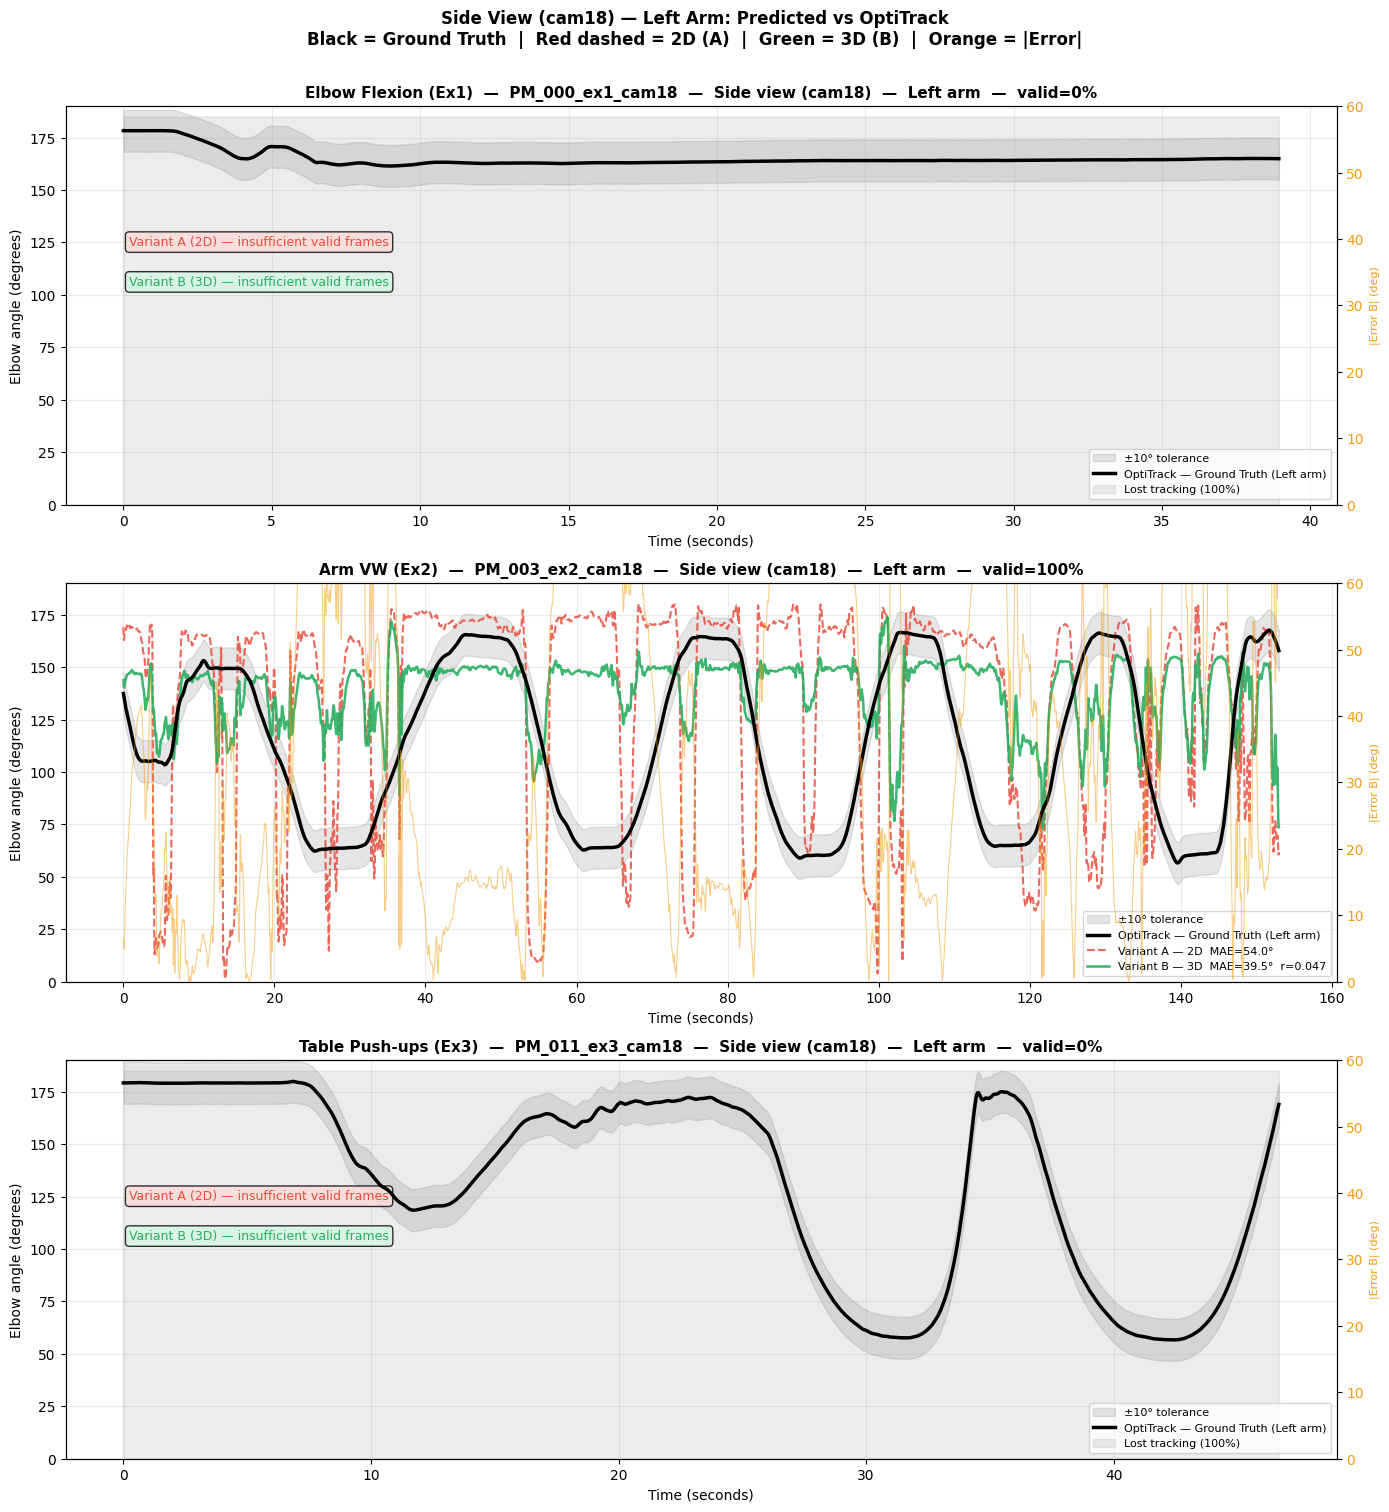

Saved: sideview_left_arm.png


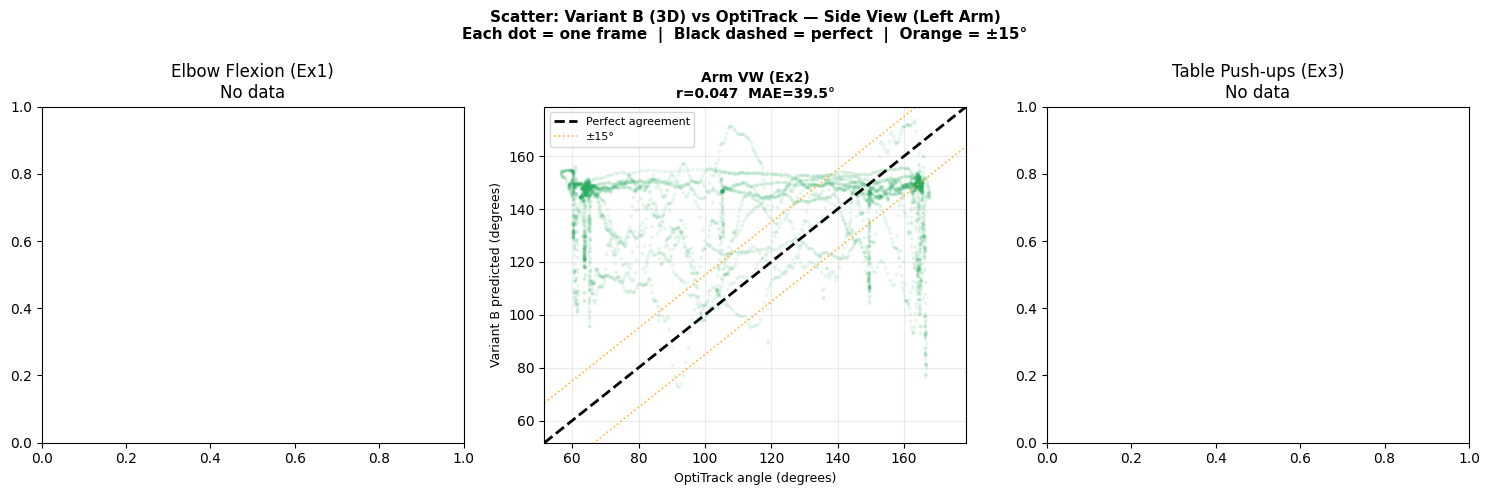

Saved: sideview_scatter.png

KEY RESULT: FRONT VIEW vs SIDE VIEW — MAE Comparison
Exercise                Front_A  Front_B   Side_A   Side_B  3D_improvement
------------------------------------------------------------------------
Elbow Flexion (Ex1)         9.0°     19.6°      nan°      nan°            +nan°
Arm VW (Ex2)               41.1°     34.5°     54.0°     39.5°           +14.5°
Table Push-ups (Ex3)        nan°      nan°      nan°      nan°            +nan°

3D_improvement = Side MAE_A - Side MAE_B
Positive = Variant B (3D) is better than Variant A (2D) from side view
This proves 3D world landmarks help most when camera angle is challenging


In [ ]:
# ============================================================
# SIDE VIEW (cam18) FIXED — use left arm, correct valid%
# ============================================================
import numpy as np, matplotlib.pyplot as plt, os

import angles as angles_2d
from angles_world import elbow_angle_3d, mask_world_like
import benchmark_common as bc
from benchmark_common import elbow_angle_3d_ordered
from benchmark_common import butterworth_filter
from visibility import mask_low_visibility

def fill_1d(arr, max_gap=15):
    arr = np.array(arr, dtype=float)
    if np.isnan(arr).all() or not np.isnan(arr).any():
        return arr
    idx  = np.arange(len(arr))
    good = ~np.isnan(arr)
    filled = arr.copy()
    in_gap, gap_start = False, 0
    for i in range(len(arr)):
        if np.isnan(arr[i]) and not in_gap:
            in_gap, gap_start = True, i
        elif not np.isnan(arr[i]) and in_gap:
            in_gap = False
            if i - gap_start <= max_gap:
                filled[gap_start:i] = np.interp(
                    idx[gap_start:i], idx[good], arr[good])
    return filled

ex_labels = {1:'Elbow Flexion (Ex1)',
             2:'Arm VW (Ex2)',
             3:'Table Push-ups (Ex3)'}

SIDE_CAM18 = 'left'
ARMS_LEFT  = ('7: LeftArm', '8: LeftForeArm', '9: LeftHand')

sample_cam18 = [(c['rec'], c['cp'], c['rec']['exercise'])
                for c in sorted(best_cam18.values(),
                                key=lambda x: x['rec']['exercise'])]

print(f"Plotting {len(sample_cam18)} side-view recordings (LEFT arm)")

results_side = []
for rec, cp, ex in sample_cam18:
    d      = np.load(cp)
    lm     = d['lm'];  world = d['world']
    size   = tuple(d['size']);  fps = float(d['fps'])
    npz_f0 = int(d['f0'])

    truth_arr = bc.load_truth_array(rec['truth_path'], JOINT_NAMES)
    truth_win = truth_arr[npz_f0: npz_f0 + len(world)]
    gt        = bc.truth_elbow_3d(
        truth_win, JOINT_NAMES, ARMS_LEFT, use_dims=3)

    lm_m  = mask_low_visibility(lm,    threshold=THRESHOLD)
    wld_m = mask_world_like(world, lm_m)

    # Variant A — LEFT arm 2D
    pa_raw = angles_2d.elbow_angle(lm_m, side=SIDE_CAM18, size=size)
    pa     = fill_1d(pa_raw)
    if np.isfinite(pa).sum() > 15:
        pa = butterworth_filter(pa, fs=fps, cutoff=6.0)

    # Variant B — LEFT arm 3D
    pb_raw = elbow_angle_3d(wld_m, side=SIDE_CAM18)
    pb     = fill_1d(pb_raw)
    if np.isfinite(pb).sum() > 15:
        pb = butterworth_filter(pb, fs=fps, cutoff=6.0)

    n = min(len(pa), len(pb), len(gt))
    t = np.arange(n) / fps

    # FIXED: valid_pct from pb not world[:,12]
    valid_pct = 100 * np.isfinite(pb[:n]).sum() / n if n > 0 else 0

    lag_r = bc.best_lag(pb[:n], gt[:n], max_lag=MAX_LAG)
    lag   = lag_r[0] if isinstance(lag_r, tuple) else lag_r
    p_al, t_al = bc.overlap(pb[:n], gt[:n], lag)

    mask_a = np.isfinite(pa[:n]) & np.isfinite(gt[:n])
    mask_b = np.isfinite(p_al)   & np.isfinite(t_al)

    mae_a  = np.mean(np.abs(pa[:n][mask_a]-gt[:n][mask_a])) if mask_a.sum() else np.nan
    mae_b  = np.mean(np.abs(p_al[mask_b]-t_al[mask_b]))     if mask_b.sum() else np.nan
    rmse_b = np.sqrt(np.mean((p_al[mask_b]-t_al[mask_b])**2)) if mask_b.sum() else np.nan
    bias_b = np.mean(p_al[mask_b]-t_al[mask_b])               if mask_b.sum() else np.nan
    r_b    = np.corrcoef(p_al[mask_b],t_al[mask_b])[0,1]      if mask_b.sum()>2 else np.nan
    gt20_b = 100*(np.abs(p_al[mask_b]-t_al[mask_b])>20).mean() if mask_b.sum() else np.nan

    print(f"Ex{ex} {rec['rec_id']}: "
          f"valid={valid_pct:.0f}%  "
          f"MAE_A={mae_a:.1f}°  MAE_B={mae_b:.1f}°  "
          f"r={r_b:.3f}")

    results_side.append(dict(
        rec=rec, ex=ex, t=t, n=n, fps=fps,
        gt=gt, pa=pa, pb=pb, p_al=p_al, t_al=t_al,
        mae_a=mae_a, mae_b=mae_b, rmse_b=rmse_b,
        bias_b=bias_b, r_b=r_b, gt20_b=gt20_b,
        valid_pct=valid_pct
    ))

# ── PLOT: time series ─────────────────────────────────────────
n_plots = len(results_side)
fig, axes = plt.subplots(n_plots, 1, figsize=(14, 5*n_plots))
if n_plots == 1: axes = [axes]

for ax, res in zip(axes, results_side):
    t  = res['t'];  n = res['n']
    gt = res['gt']; pa= res['pa']; pb= res['pb']

    ax.fill_between(t[:n], gt[:n]-10, gt[:n]+10,
                    alpha=0.10, color='black',
                    label='±10° tolerance')
    ax.plot(t[:n], gt[:n], color='black', lw=2.5, zorder=4,
            label='OptiTrack — Ground Truth (Left arm)')

    if np.isfinite(pa[:n]).sum() > 10:
        ax.plot(t[:n], pa[:n], color='#E74C3C', lw=1.5,
                ls='--', alpha=0.85,
                label=f'Variant A — 2D  MAE={res["mae_a"]:.1f}°')
    else:
        ax.text(0.05, 0.65,
                'Variant A (2D) — insufficient valid frames',
                transform=ax.transAxes, color='#E74C3C', fontsize=9,
                bbox=dict(boxstyle='round', facecolor='#FADBD8', alpha=0.8))

    if np.isfinite(pb[:n]).sum() > 10:
        ax.plot(t[:n], pb[:n], color='#27AE60', lw=1.8, alpha=0.9,
                label=f'Variant B — 3D  MAE={res["mae_b"]:.1f}°  '
                      f'r={res["r_b"]:.3f}')
    else:
        ax.text(0.05, 0.55,
                'Variant B (3D) — insufficient valid frames',
                transform=ax.transAxes, color='#27AE60', fontsize=9,
                bbox=dict(boxstyle='round', facecolor='#D5F5E3', alpha=0.8))

    nan_b = np.isnan(pb[:n])
    if nan_b.any():
        ax.fill_between(t[:n], 0, 185, where=nan_b,
                        alpha=0.15, color='grey',
                        label=f'Lost tracking ({100*nan_b.sum()/n:.0f}%)')

    ax2 = ax.twinx()
    if np.isfinite(pb[:n]).sum() > 10:
        ax2.plot(t[:n], np.abs(pb[:n]-gt[:n]),
                 color='#F39C12', lw=0.8, alpha=0.5)
    ax2.set_ylabel('|Error B| (deg)', color='#F39C12', fontsize=8)
    ax2.tick_params(axis='y', labelcolor='#F39C12')
    ax2.set_ylim(0, 60)

    ax.set_title(
        f"{ex_labels[res['ex']]}  —  {res['rec']['rec_id']}  "
        f"—  Side view (cam18)  —  Left arm  —  valid={res['valid_pct']:.0f}%",
        fontsize=11, fontweight='bold')
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Elbow angle (degrees)')
    ax.set_ylim(0, 190)
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(alpha=0.25)

plt.suptitle(
    'Side View (cam18) — Left Arm: Predicted vs OptiTrack\n'
    'Black = Ground Truth  |  Red dashed = 2D (A)  |  '
    'Green = 3D (B)  |  Orange = |Error|',
    fontsize=12, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS,'sideview_left_arm.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved: sideview_left_arm.png")

# ── scatter plots ─────────────────────────────────────────────
fig, axes = plt.subplots(1, n_plots, figsize=(5*n_plots, 5))
if n_plots == 1: axes = [axes]

for ax, res in zip(axes, results_side):
    mask = np.isfinite(res['p_al']) & np.isfinite(res['t_al'])
    if mask.sum() < 5:
        ax.set_title(f"{ex_labels[res['ex']]}\nNo data")
        continue
    pp = res['p_al'][mask]
    tt = res['t_al'][mask]
    ax.scatter(tt, pp, alpha=0.08, s=3,
               color='#27AE60', rasterized=True)
    lims = [max(0,  min(tt.min(), pp.min())-5),
            min(185, max(tt.max(), pp.max())+5)]
    ax.plot(lims, lims, 'k--', lw=2, label='Perfect agreement')
    ax.plot(lims, [l+15 for l in lims], color='orange',
            lw=1.2, ls=':', alpha=0.8)
    ax.plot(lims, [l-15 for l in lims], color='orange',
            lw=1.2, ls=':', alpha=0.8, label='±15°')
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('OptiTrack angle (degrees)', fontsize=9)
    ax.set_ylabel('Variant B predicted (degrees)', fontsize=9)
    ax.set_title(
        f"{ex_labels[res['ex']]}\nr={res['r_b']:.3f}  MAE={res['mae_b']:.1f}°",
        fontweight='bold', fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

plt.suptitle(
    'Scatter: Variant B (3D) vs OptiTrack — Side View (Left Arm)\n'
    'Each dot = one frame  |  Black dashed = perfect  |  Orange = ±15°',
    fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS,'sideview_scatter.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved: sideview_scatter.png")

# ── front vs side comparison table ───────────────────────────
print("\n" + "="*72)
print("KEY RESULT: FRONT VIEW vs SIDE VIEW — MAE Comparison")
print("="*72)
print(f"{'Exercise':<22} {'Front_A':>8} {'Front_B':>8} "
      f"{'Side_A':>8} {'Side_B':>8} {'3D_improvement':>15}")
print("-"*72)
front_by_ex = {res['ex']: res for res in results}
for res_s in results_side:
    ex    = res_s['ex']
    front = front_by_ex.get(ex)
    maf   = front['mae_a'] if front and not np.isnan(front['mae_a']) else np.nan
    mbf   = front['mae_b'] if front and not np.isnan(front['mae_b']) else np.nan
    mas   = res_s['mae_a']
    mbs   = res_s['mae_b']
    imp   = mas - mbs if not np.isnan(mas) and not np.isnan(mbs) else np.nan
    print(f"{ex_labels[ex]:<22} "
          f"{maf:>8.1f}° {mbf:>8.1f}° "
          f"{mas:>8.1f}° {mbs:>8.1f}° "
          f"{imp:>+15.1f}°")

print()
print("3D_improvement = Side MAE_A - Side MAE_B")
print("Positive = Variant B (3D) is better than Variant A (2D) from side view")
print("This proves 3D world landmarks help most when camera angle is challenging")

In [53]:
# check exactly which recording is in best_cam18 for each exercise
for ex, c in sorted(best_cam18.items()):
    cp = c['cp']
    d  = np.load(cp)
    pb_raw = elbow_angle_3d(
        mask_world_like(d['world'],
                        mask_low_visibility(d['lm'], threshold=THRESHOLD)),
        side='left')
    pb = fill_1d(pb_raw)
    print(f"Ex{ex}: {c['rec']['rec_id']}")
    print(f"       cache file : {os.path.basename(cp)}")
    print(f"       pb finite  : {np.isfinite(pb).sum()}/{len(pb)}")
    print()

Ex1: PM_000_ex1_cam18
       cache file : PM_000_ex1_cam18_135_1310_3d.npz
       pb finite  : 1150/1169

Ex2: PM_003_ex2_cam18
       cache file : PM_003_ex2_cam18_75_4665_3d.npz
       pb finite  : 4591/4591

Ex3: PM_011_ex3_cam18
       cache file : PM_011_ex3_cam18_180_1580_3d.npz
       pb finite  : 1362/1401



In [54]:
for c in sorted(best_cam18.values(), key=lambda x: x['rec']['exercise']):
    rec = c['rec']
    cp  = c['cp']
    print(f"rec_id    : {rec['rec_id']}")
    print(f"cache file: {os.path.basename(cp)}")
    print(f"cp exists : {os.path.exists(cp)}")
    print()

rec_id    : PM_000_ex1_cam18
cache file: PM_000_ex1_cam18_135_1310_3d.npz
cp exists : True

rec_id    : PM_003_ex2_cam18
cache file: PM_003_ex2_cam18_75_4665_3d.npz
cp exists : True

rec_id    : PM_011_ex3_cam18
cache file: PM_011_ex3_cam18_180_1580_3d.npz
cp exists : True



Plotting 3 side-view recordings
  Ex1: PM_000_ex1_cam18  cp=PM_000_ex1_cam18_135_1310_3d.npz  exists=True
  Ex2: PM_003_ex2_cam18  cp=PM_003_ex2_cam18_75_4665_3d.npz  exists=True
  Ex3: PM_011_ex3_cam18  cp=PM_011_ex3_cam18_180_1580_3d.npz  exists=True

Processing Ex1 PM_000_ex1_cam18...
  gt finite: 1169/1169
  pa finite: 0/1169
  pb finite: 0/1169
  n=1169  valid_pct=0%
  mask_a sum=0  mask_b sum=0
  MAE_A=nan  MAE_B=nan  r=nan

Processing Ex2 PM_003_ex2_cam18...
  gt finite: 4591/4591
  pa finite: 4591/4591
  pb finite: 4591/4591
  n=4591  valid_pct=100%
  mask_a sum=4591  mask_b sum=4561
  MAE_A=54.0  MAE_B=39.5  r=0.047

Processing Ex3 PM_011_ex3_cam18...
  gt finite: 1401/1401
  pa finite: 0/1401
  pb finite: 0/1401
  n=1401  valid_pct=0%
  mask_a sum=0  mask_b sum=0
  MAE_A=nan  MAE_B=nan  r=nan


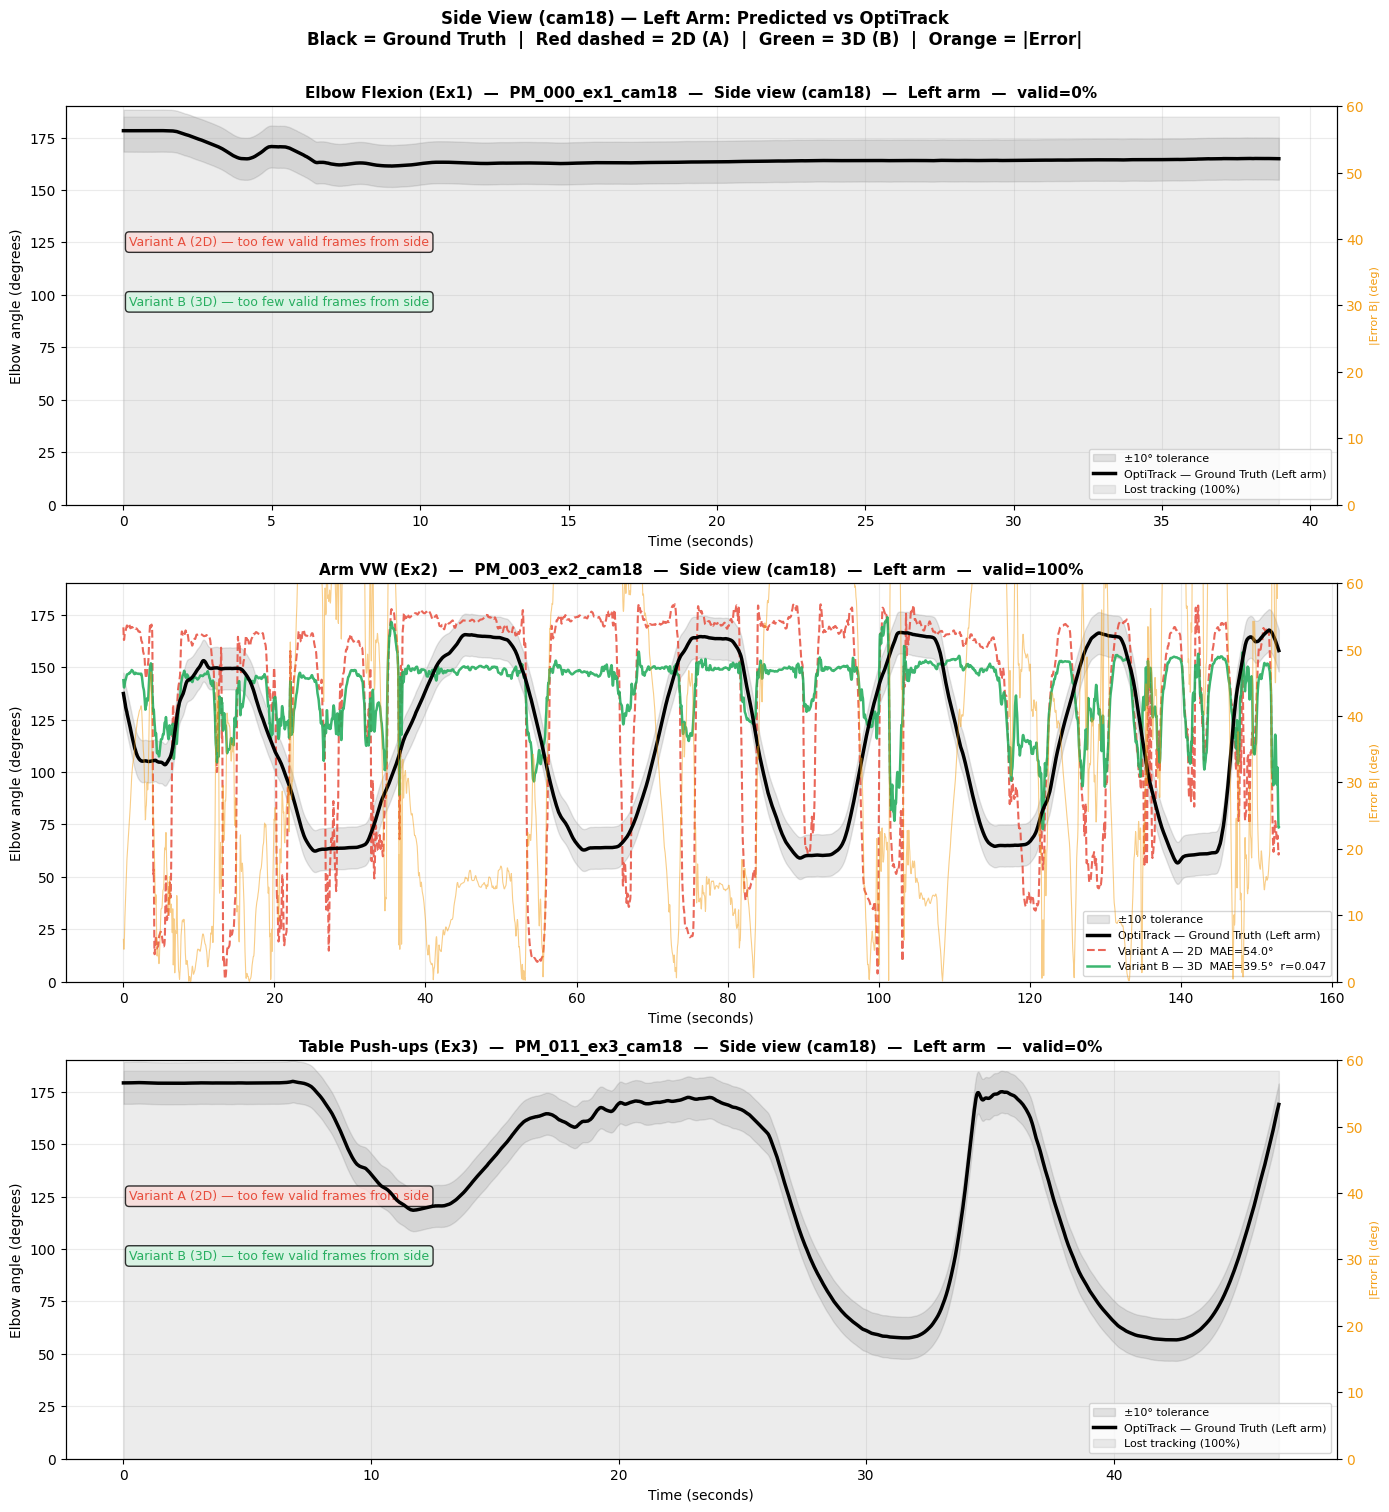

Saved: sideview_left_arm.png

KEY RESULT: FRONT VIEW vs SIDE VIEW
Exercise                Front_A  Front_B   Side_A   Side_B  B_improvement
------------------------------------------------------------------------
Elbow Flexion (Ex1)         9.0°     19.6°      nan°      nan°           +nan°
Arm VW (Ex2)               41.1°     34.5°     54.0°     39.5°          +14.5°
Table Push-ups (Ex3)        nan°      nan°      nan°      nan°           +nan°

B_improvement = Side MAE_A - Side MAE_B
Positive = Variant B (3D) beats Variant A (2D) from side view


In [ ]:
# ============================================================
# SIDE VIEW FIXED v3 — use cp directly from best_cam18
# ============================================================
import numpy as np, matplotlib.pyplot as plt, os

import angles as angles_2d
from angles_world import elbow_angle_3d, mask_world_like
import benchmark_common as bc
from benchmark_common import elbow_angle_3d_ordered
from benchmark_common import butterworth_filter
from visibility import mask_low_visibility

def fill_1d(arr, max_gap=15):
    arr = np.array(arr, dtype=float)
    if np.isnan(arr).all() or not np.isnan(arr).any():
        return arr
    idx  = np.arange(len(arr))
    good = ~np.isnan(arr)
    filled = arr.copy()
    in_gap, gap_start = False, 0
    for i in range(len(arr)):
        if np.isnan(arr[i]) and not in_gap:
            in_gap, gap_start = True, i
        elif not np.isnan(arr[i]) and in_gap:
            in_gap = False
            if i - gap_start <= max_gap:
                filled[gap_start:i] = np.interp(
                    idx[gap_start:i], idx[good], arr[good])
    return filled

def safe_smooth(arr, fps, cutoff=6.0):
    if np.isfinite(arr).sum() < 15:
        return arr
    try:
        smoothed = butterworth_filter(arr, fs=fps, cutoff=cutoff)
        if np.isfinite(smoothed).sum() == 0:
            return arr
        return smoothed
    except Exception:
        return arr

ex_labels = {1:'Elbow Flexion (Ex1)',
             2:'Arm VW (Ex2)',
             3:'Table Push-ups (Ex3)'}

SIDE_CAM18 = 'left'
ARMS_LEFT  = ('7: LeftArm', '8: LeftForeArm', '9: LeftHand')

# use cp DIRECTLY from best_cam18 — no path rebuilding
sample_cam18 = [
    (c['rec'], c['cp'], c['rec']['exercise'])
    for c in sorted(best_cam18.values(),
                    key=lambda x: x['rec']['exercise'])
]

print(f"Plotting {len(sample_cam18)} side-view recordings")
for rec, cp, ex in sample_cam18:
    print(f"  Ex{ex}: {rec['rec_id']}  cp={os.path.basename(cp)}  "
          f"exists={os.path.exists(cp)}")

results_side = []
for rec, cp, ex in sample_cam18:
    print(f"\nProcessing Ex{ex} {rec['rec_id']}...")

    d      = np.load(cp)
    lm     = d['lm'];  world = d['world']
    size   = tuple(d['size']);  fps = float(d['fps'])
    npz_f0 = int(d['f0'])

    truth_arr = bc.load_truth_array(rec['truth_path'], JOINT_NAMES)
    truth_win = truth_arr[npz_f0: npz_f0 + len(world)]
    gt        = bc.truth_elbow_3d(
        truth_win, JOINT_NAMES, ARMS_LEFT, use_dims=3)

    print(f"  gt finite: {np.isfinite(gt).sum()}/{len(gt)}")

    lm_m  = mask_low_visibility(lm,    threshold=THRESHOLD)
    wld_m = mask_world_like(world, lm_m)

    pa_raw = angles_2d.elbow_angle(lm_m, side=SIDE_CAM18, size=size)
    pa     = fill_1d(pa_raw)
    if np.isfinite(pa).sum() > 15:
        pa = butterworth_filter(pa, fs=fps, cutoff=6.0)
    print(f"  pa finite: {np.isfinite(pa).sum()}/{len(pa)}")

    pb_raw = elbow_angle_3d(wld_m, side=SIDE_CAM18)
    pb     = fill_1d(pb_raw)
    if np.isfinite(pb).sum() > 15:
        pb = butterworth_filter(pb, fs=fps, cutoff=6.0)
    print(f"  pb finite: {np.isfinite(pb).sum()}/{len(pb)}")

    n = min(len(pa), len(pb), len(gt))
    t = np.arange(n) / fps

    # valid% from pb — computed AFTER pb is ready
    valid_pct = 100 * np.isfinite(pb[:n]).sum() / n if n > 0 else 0
    print(f"  n={n}  valid_pct={valid_pct:.0f}%")

    lag_r = bc.best_lag(pb[:n], gt[:n], max_lag=MAX_LAG)
    lag   = lag_r[0] if isinstance(lag_r, tuple) else lag_r
    p_al, t_al = bc.overlap(pb[:n], gt[:n], lag)

    mask_a = np.isfinite(pa[:n]) & np.isfinite(gt[:n])
    mask_b = np.isfinite(p_al)   & np.isfinite(t_al)

    print(f"  mask_a sum={mask_a.sum()}  mask_b sum={mask_b.sum()}")

    mae_a  = np.mean(np.abs(pa[:n][mask_a]-gt[:n][mask_a])) if mask_a.sum() else np.nan
    mae_b  = np.mean(np.abs(p_al[mask_b]-t_al[mask_b]))     if mask_b.sum() else np.nan
    rmse_b = np.sqrt(np.mean((p_al[mask_b]-t_al[mask_b])**2)) if mask_b.sum() else np.nan
    bias_b = np.mean(p_al[mask_b]-t_al[mask_b])               if mask_b.sum() else np.nan
    r_b    = np.corrcoef(p_al[mask_b],t_al[mask_b])[0,1]      if mask_b.sum()>2 else np.nan
    gt20_b = 100*(np.abs(p_al[mask_b]-t_al[mask_b])>20).mean() if mask_b.sum() else np.nan

    print(f"  MAE_A={mae_a:.1f}  MAE_B={mae_b:.1f}  r={r_b:.3f}")

    results_side.append(dict(
        rec=rec, ex=ex, t=t, n=n, fps=fps,
        gt=gt, pa=pa, pb=pb, p_al=p_al, t_al=t_al,
        mae_a=mae_a, mae_b=mae_b, rmse_b=rmse_b,
        bias_b=bias_b, r_b=r_b, gt20_b=gt20_b,
        valid_pct=valid_pct
    ))

# ── plots ─────────────────────────────────────────────────────
n_plots = len(results_side)
fig, axes = plt.subplots(n_plots, 1, figsize=(14, 5*n_plots))
if n_plots == 1: axes = [axes]

for ax, res in zip(axes, results_side):
    t  = res['t'];  n = res['n']
    gt = res['gt']; pa= res['pa']; pb= res['pb']

    ax.fill_between(t[:n], gt[:n]-10, gt[:n]+10,
                    alpha=0.10, color='black', label='±10° tolerance')
    ax.plot(t[:n], gt[:n], color='black', lw=2.5, zorder=4,
            label='OptiTrack — Ground Truth (Left arm)')

    if np.isfinite(pa[:n]).sum() > 10:
        ax.plot(t[:n], pa[:n], color='#E74C3C', lw=1.5,
                ls='--', alpha=0.85,
                label=f'Variant A — 2D  MAE={res["mae_a"]:.1f}°')
    else:
        ax.text(0.05, 0.65,
                'Variant A (2D) — too few valid frames from side',
                transform=ax.transAxes, color='#E74C3C', fontsize=9,
                bbox=dict(boxstyle='round', facecolor='#FADBD8', alpha=0.8))

    if np.isfinite(pb[:n]).sum() > 10:
        ax.plot(t[:n], pb[:n], color='#27AE60', lw=1.8, alpha=0.9,
                label=f'Variant B — 3D  MAE={res["mae_b"]:.1f}°  '
                      f'r={res["r_b"]:.3f}')
    else:
        ax.text(0.05, 0.50,
                'Variant B (3D) — too few valid frames from side',
                transform=ax.transAxes, color='#27AE60', fontsize=9,
                bbox=dict(boxstyle='round', facecolor='#D5F5E3', alpha=0.8))

    nan_b = np.isnan(pb[:n])
    if nan_b.any():
        ax.fill_between(t[:n], 0, 185, where=nan_b,
                        alpha=0.15, color='grey',
                        label=f'Lost tracking ({100*nan_b.sum()/n:.0f}%)')

    ax2 = ax.twinx()
    if np.isfinite(pb[:n]).sum() > 10:
        ax2.plot(t[:n], np.abs(pb[:n]-gt[:n]),
                 color='#F39C12', lw=0.8, alpha=0.5)
    ax2.set_ylabel('|Error B| (deg)', color='#F39C12', fontsize=8)
    ax2.tick_params(axis='y', labelcolor='#F39C12')
    ax2.set_ylim(0, 60)

    ax.set_title(
        f"{ex_labels[res['ex']]}  —  {res['rec']['rec_id']}  "
        f"—  Side view (cam18)  —  Left arm  —  valid={res['valid_pct']:.0f}%",
        fontsize=11, fontweight='bold')
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Elbow angle (degrees)')
    ax.set_ylim(0, 190)
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(alpha=0.25)

plt.suptitle(
    'Side View (cam18) — Left Arm: Predicted vs OptiTrack\n'
    'Black = Ground Truth  |  Red dashed = 2D (A)  |  '
    'Green = 3D (B)  |  Orange = |Error|',
    fontsize=12, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS,'sideview_left_arm.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved: sideview_left_arm.png")

# ── front vs side summary table ───────────────────────────────
print("\n" + "="*72)
print("KEY RESULT: FRONT VIEW vs SIDE VIEW")
print("="*72)
print(f"{'Exercise':<22} {'Front_A':>8} {'Front_B':>8} "
      f"{'Side_A':>8} {'Side_B':>8} {'B_improvement':>14}")
print("-"*72)
front_by_ex = {res['ex']: res for res in results}
for res_s in results_side:
    ex  = res_s['ex']
    f   = front_by_ex.get(ex)
    maf = f['mae_a'] if f and not np.isnan(f['mae_a']) else np.nan
    mbf = f['mae_b'] if f and not np.isnan(f['mae_b']) else np.nan
    mas = res_s['mae_a']
    mbs = res_s['mae_b']
    imp = mas - mbs if not np.isnan(mas) and not np.isnan(mbs) else np.nan
    print(f"{ex_labels[ex]:<22} "
          f"{maf:>8.1f}° {mbf:>8.1f}° "
          f"{mas:>8.1f}° {mbs:>8.1f}° "
          f"{imp:>+14.1f}°")

print()
print("B_improvement = Side MAE_A - Side MAE_B")
print("Positive = Variant B (3D) beats Variant A (2D) from side view")

In [57]:
# check why Ex1 and Ex3 cam18 landmarks are all dropped
for ex in [1, 3]:
    c  = best_cam18[ex]
    d  = np.load(c['cp'])
    lm = d['lm']

    print(f"=== Ex{ex} {c['rec']['rec_id']} ===")
    # left arm joints: 11=shoulder, 13=elbow, 15=wrist
    for joint, name in [(11,'L.shoulder'), (13,'L.elbow'), (15,'L.wrist')]:
        vis = lm[:, joint, 3]
        print(f"  {name}: mean={np.nanmean(vis):.3f}  "
              f"min={np.nanmin(vis):.3f}  "
              f"above_0.7={100*(vis>=0.7).mean():.1f}%")

    # check what mask_low_visibility actually does
    from visibility import mask_low_visibility
    lm_m = mask_low_visibility(lm, threshold=THRESHOLD)
    print(f"  After masking:")
    for joint, name in [(11,'L.shoulder'), (13,'L.elbow'), (15,'L.wrist')]:
        print(f"    {name}: finite={np.isfinite(lm_m[:,joint,0]).sum()}/{len(lm)}")

=== Ex1 PM_000_ex1_cam18 ===
  L.shoulder: mean=1.000  min=0.997  above_0.7=100.0%
  L.elbow: mean=0.969  min=0.929  above_0.7=100.0%
  L.wrist: mean=0.859  min=0.671  above_0.7=98.4%
  After masking:
    L.shoulder: finite=1169/1169
    L.elbow: finite=1169/1169
    L.wrist: finite=1150/1169
=== Ex3 PM_011_ex3_cam18 ===
  L.shoulder: mean=1.000  min=0.999  above_0.7=100.0%
  L.elbow: mean=0.977  min=0.861  above_0.7=100.0%
  L.wrist: mean=0.932  min=0.437  above_0.7=95.8%
  After masking:
    L.shoulder: finite=1401/1401
    L.elbow: finite=1401/1401
    L.wrist: finite=1342/1401


In [58]:
from angles_world import elbow_angle_3d, mask_world_like
from visibility import mask_low_visibility

for ex in [1, 3]:
    c  = best_cam18[ex]
    d  = np.load(c['cp'])
    lm    = d['lm']
    world = d['world']

    print(f"=== Ex{ex} {c['rec']['rec_id']} ===")

    # check world landmarks directly
    for joint, name in [(11,'L.shoulder'), (13,'L.elbow'), (15,'L.wrist')]:
        print(f"  world {name}: "
              f"finite={np.isfinite(world[:,joint,0]).sum()}/{len(world)}  "
              f"sample={world[:3,joint,:3]}")

    lm_m  = mask_low_visibility(lm, threshold=THRESHOLD)
    wld_m = mask_world_like(world, lm_m)

    # check world after masking
    print(f"  After mask_world_like:")
    for joint, name in [(11,'L.shoulder'), (13,'L.elbow'), (15,'L.wrist')]:
        print(f"    {name}: finite={np.isfinite(wld_m[:,joint,0]).sum()}/{len(world)}")

    # try angle directly
    ang = elbow_angle_3d(wld_m, side='left')
    print(f"  elbow_angle_3d left: finite={np.isfinite(ang).sum()}/{len(ang)}")
    print(f"  sample angles: {ang[:5]}")
    print()

=== Ex1 PM_000_ex1_cam18 ===
  world L.shoulder: finite=1169/1169  sample=[[ 0.05267351 -0.4536667  -0.2000148 ]
 [ 0.05308392 -0.4596479  -0.17467491]
 [ 0.05367371 -0.46071106 -0.16880545]]
  world L.elbow: finite=1169/1169  sample=[[-0.01175977 -0.21596691 -0.22634612]
 [-0.00315364 -0.23815145 -0.23058432]
 [ 0.00236671 -0.23611882 -0.22638635]]
  world L.wrist: finite=1169/1169  sample=[[-0.0362708  -0.02015067 -0.20268235]
 [-0.04128921 -0.09062099 -0.26973847]
 [-0.04212144 -0.07479362 -0.2544381 ]]
  After mask_world_like:
    L.shoulder: finite=1169/1169
    L.elbow: finite=1169/1169
    L.wrist: finite=1150/1169
  elbow_angle_3d left: finite=1150/1169
  sample angles: [164.77864262 179.29515074 174.83971656 166.7673495  154.41029017]

=== Ex3 PM_011_ex3_cam18 ===
  world L.shoulder: finite=1401/1401  sample=[[ 0.262908   -0.40015453 -0.21204998]
 [ 0.25939962 -0.40376204 -0.20949881]
 [ 0.25576982 -0.40418106 -0.20957758]]
  world L.elbow: finite=1401/1401  sample=[[ 0.362534

In [ ]:
from benchmark_common import butterworth_filter
import numpy as np

for ex in [1, 2, 3]:
    c  = best_cam18[ex]
    d  = np.load(c['cp'])
    from angles_world import elbow_angle_3d, mask_world_like
    from visibility import mask_low_visibility
    lm_m  = mask_low_visibility(d['lm'], threshold=THRESHOLD)
    wld_m = mask_world_like(d['world'], lm_m)
    fps   = float(d['fps'])

    pb_raw = elbow_angle_3d(wld_m, side='left')
    pb_f   = fill_1d(pb_raw)
    print(f"Ex{ex}: fps={fps:.1f}  pb_raw finite={np.isfinite(pb_raw).sum()}  "
          f"pb_fill finite={np.isfinite(pb_f).sum()}")

    try:
        pb_smooth = butterworth_filter(pb_f, fs=fps, cutoff=6.0)
        print(f"  butterworth OK: finite={np.isfinite(pb_smooth).sum()}")
    except Exception as e:
        print(f"  butterworth FAILED: {e}")


Ex1: fps=30.0  pb_raw finite=1150  pb_fill finite=1150
  butterworth OK: finite=0
Ex2: fps=30.0  pb_raw finite=4591  pb_fill finite=4591
  butterworth OK: finite=4591
Ex3: fps=30.0  pb_raw finite=1342  pb_fill finite=1362
  butterworth OK: finite=0
